In [1]:
import torch
torch.set_num_threads(4)
import os
import glob
import math
import gc
import numpy as np
from PIL import Image
from tqdm import tqdm
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split, ConcatDataset
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from pytorch_msssim import ms_ssim
import torchvision.transforms.functional as TF
import json
import random

# ============================================================================
# 0. Utilities
# ============================================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10):
    positions = []
    start_x = -(n_led_x - 1) * pitch_x / 2.0
    start_y = -(n_led_y - 1) * pitch_y / 2.0
    for i in range(n_led_x):
        for j in range(n_led_y):
            positions.append((start_x + i * pitch_x, start_y + j * pitch_y, distance_z))
    return positions

def init_weights(m):
    """Kaiming Normal initialization to prevent vanishing gradients."""
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)
    elif isinstance(m, nn.GroupNorm):
        nn.init.constant_(m.weight, 1)
        nn.init.constant_(m.bias, 0)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ============================================================================
# 1. Architectural Building Blocks & Attention Modules
# ============================================================================
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        reduced = max(in_planes // ratio, 1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, reduced, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(reduced, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, padding_mode='reflect', bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))

# --- Ablation Wrappers ---
class ChannelAttentionBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.ca = ChannelAttention(channels)
    def forward(self, x):
        return x * self.ca(x)

class SpatialAttentionBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = SpatialAttention()
    def forward(self, x):
        return x * self.sa(x)

class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(channels, ratio=reduction)
        self.sa = SpatialAttention()
    def forward(self, x):
        return x * self.ca(x) * self.sa(x)

class SpectralGatingBlock(nn.Module):
    """Explicitly processes spatial frequencies of holographic diffraction patterns via 2D FFT."""
    def __init__(self, channels):
        super().__init__()
        self.conv_spatial = nn.Sequential(nn.Conv2d(channels, channels, 1, bias=False), nn.GELU())
        self.weights_real = nn.Parameter(torch.randn(1, channels, 1, 1) * 0.02)
        self.weights_imag = nn.Parameter(torch.randn(1, channels, 1, 1) * 0.02)
    def forward(self, x):
        spatial_out = self.conv_spatial(x)
        x_fft = torch.fft.fft2(x, dim=(-2, -1), norm='ortho')
        real = x_fft.real * self.weights_real - x_fft.imag * self.weights_imag
        imag = x_fft.real * self.weights_imag + x_fft.imag * self.weights_real
        x_weighted = torch.complex(real, imag)
        spectral_out = torch.fft.ifft2(x_weighted, dim=(-2, -1), norm='ortho').real
        return spatial_out + spectral_out

class FeatureAlign(nn.Module):
    def __init__(self, channels, num_inputs=5):
        super().__init__()
        self.alignments = nn.ModuleList([nn.Conv2d(channels, channels, kernel_size=1, bias=False) for _ in range(num_inputs)])
    def forward(self, features):
        return torch.cat([align(f) for align, f in zip(self.alignments, features)], dim=1)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, activation=True, num_groups=8):
        super().__init__()
        layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, padding_mode='reflect', bias=False)]
        if activation:
            groups = num_groups if out_ch % num_groups == 0 else 1
            layers.append(nn.GroupNorm(num_groups=groups, num_channels=out_ch))
            layers.append(nn.GELU())
        self.conv = nn.Sequential(*layers)
    def forward(self, x):
        return self.conv(x)

class Encoder(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBlock(in_ch, out_ch)
        self.conv2 = ConvBlock(out_ch, out_ch)
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()
        self.pool = nn.Conv2d(out_ch, out_ch, kernel_size=2, stride=2, bias=False)
    def forward(self, x):
        skip = self.conv2(self.conv1(x)) + self.shortcut(x)
        return skip, self.pool(skip)

class Bottleneck(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = ConvBlock(in_ch, out_ch)
        self.conv2 = ConvBlock(out_ch, out_ch)
        self.shortcut = nn.Conv2d(in_ch, out_ch, 1, bias=False)
    def forward(self, x):
        return self.conv2(self.conv1(x)) + self.shortcut(x)

def make_upsample(in_ch, out_ch, scale_factor):
    inter_ch = out_ch * (scale_factor ** 2)
    return nn.Sequential(
        nn.Conv2d(in_ch, inter_ch, kernel_size=3, padding=1, padding_mode='reflect', bias=False),
        nn.PixelShuffle(scale_factor),
        nn.GroupNorm(num_groups=8 if out_ch % 8 == 0 else 1, num_channels=out_ch),
        nn.GELU()
    )

def make_downsample(in_ch, out_ch, scale_factor):
    return nn.Sequential(
        nn.Conv2d(in_ch, in_ch, kernel_size=scale_factor, stride=scale_factor, bias=False),
        ConvBlock(in_ch, out_ch)
    )

# ============================================================================
# 2. Architectures (Plain UNet, UNet++, AblationUNet3+)
# ============================================================================

# --- Variant 1: Plain U-Net ---
class PlainUNet(nn.Module):
    """Standard U-Net baseline with only same-scale skip connections (Variant 1)."""
    def __init__(self, in_channels=12, out_channels=2):
        super().__init__()
        self.e1 = Encoder(in_channels, 32)
        self.e2 = Encoder(32, 64)
        self.e3 = Encoder(64, 128)
        self.e4 = Encoder(128, 256)
        self.e5 = Bottleneck(256, 512)
        
        self.up4 = make_upsample(512, 256, 2)
        self.d4 = ConvBlock(512, 256)
        
        self.up3 = make_upsample(256, 128, 2)
        self.d3 = ConvBlock(256, 128)
        
        self.up2 = make_upsample(128, 64, 2)
        self.d2 = ConvBlock(128, 64)
        
        self.up1 = make_upsample(64, 32, 2)
        self.d1 = ConvBlock(64, 32)
        
        self.final = nn.Conv2d(32, out_channels, kernel_size=3, padding=1, padding_mode='reflect')
        self.apply(init_weights)
        self.final.weight.data *= 0.01
        if self.final.bias is not None:
            self.final.bias.data.zero_()

    def forward(self, inputs):
        e1, p1 = self.e1(inputs)
        e2, p2 = self.e2(p1)
        e3, p3 = self.e3(p2)
        e4, p4 = self.e4(p3)
        e5 = self.e5(p4)
        
        d4 = self.d4(torch.cat([self.up4(e5), e4], dim=1))
        d3 = self.d3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.d2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.d1(torch.cat([self.up1(d2), e1], dim=1))
        
        out = self.final(d1)
        pred_amp = torch.sigmoid(out[:, 0:1, :, :])
        pred_phase = torch.tanh(out[:, 1:2, :, :]) * math.pi
        return pred_amp, pred_phase

# --- Variant 2: UNet++ ---
class ConvBlock_PlusPlus(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, padding_mode='reflect', bias=False),
            nn.GroupNorm(num_groups=8 if out_ch % 8 == 0 else 1, num_channels=out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, padding_mode='reflect', bias=False),
            nn.GroupNorm(num_groups=8 if out_ch % 8 == 0 else 1, num_channels=out_ch),
            nn.GELU()
        )
    def forward(self, x):
        return self.conv(x)

class UNetPlusPlus(nn.Module):
    """UNet++ architecture with nested skip connections."""
    def __init__(self, in_channels=12, out_channels=2):
        super().__init__()
        
        filters = [32, 64, 128, 256, 512]
        
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        
        # Encoder
        self.conv0_0 = ConvBlock_PlusPlus(in_channels, filters[0])
        self.conv1_0 = ConvBlock_PlusPlus(filters[0], filters[1])
        self.conv2_0 = ConvBlock_PlusPlus(filters[1], filters[2])
        self.conv3_0 = ConvBlock_PlusPlus(filters[2], filters[3])
        self.conv4_0 = ConvBlock_PlusPlus(filters[3], filters[4])
        
        # Nested Decoders
        self.conv0_1 = ConvBlock_PlusPlus(filters[0] + filters[1], filters[0])
        self.conv1_1 = ConvBlock_PlusPlus(filters[1] + filters[2], filters[1])
        self.conv2_1 = ConvBlock_PlusPlus(filters[2] + filters[3], filters[2])
        self.conv3_1 = ConvBlock_PlusPlus(filters[3] + filters[4], filters[3])
        
        self.conv0_2 = ConvBlock_PlusPlus(filters[0]*2 + filters[1], filters[0])
        self.conv1_2 = ConvBlock_PlusPlus(filters[1]*2 + filters[2], filters[1])
        self.conv2_2 = ConvBlock_PlusPlus(filters[2]*2 + filters[3], filters[2])
        
        self.conv0_3 = ConvBlock_PlusPlus(filters[0]*3 + filters[1], filters[0])
        self.conv1_3 = ConvBlock_PlusPlus(filters[1]*3 + filters[2], filters[1])
        
        self.conv0_4 = ConvBlock_PlusPlus(filters[0]*4 + filters[1], filters[0])
        
        self.final = nn.Conv2d(filters[0], out_channels, kernel_size=3, padding=1, padding_mode='reflect')
        self.apply(init_weights)
        self.final.weight.data *= 0.01
        if self.final.bias is not None:
            self.final.bias.data.zero_()

    def forward(self, x):
        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x0_1 = self.conv0_1(torch.cat([x0_0, self.up(x1_0)], 1))
        
        x2_0 = self.conv2_0(self.pool(x1_0))
        x1_1 = self.conv1_1(torch.cat([x1_0, self.up(x2_0)], 1))
        x0_2 = self.conv0_2(torch.cat([x0_0, x0_1, self.up(x1_1)], 1))
        
        x3_0 = self.conv3_0(self.pool(x2_0))
        x2_1 = self.conv2_1(torch.cat([x2_0, self.up(x3_0)], 1))
        x1_2 = self.conv1_2(torch.cat([x1_0, x1_1, self.up(x2_1)], 1))
        x0_3 = self.conv0_3(torch.cat([x0_0, x0_1, x0_2, self.up(x1_2)], 1))
        
        x4_0 = self.conv4_0(self.pool(x3_0))
        x3_1 = self.conv3_1(torch.cat([x3_0, self.up(x4_0)], 1))
        x2_2 = self.conv2_2(torch.cat([x2_0, x2_1, self.up(x3_1)], 1))
        x1_3 = self.conv1_3(torch.cat([x1_0, x1_1, x1_2, self.up(x2_2)], 1))
        x0_4 = self.conv0_4(torch.cat([x0_0, x0_1, x0_2, x0_3, self.up(x1_3)], 1))
        
        out = self.final(x0_4)
        pred_amp = torch.sigmoid(out[:, 0:1, :, :])
        pred_phase = torch.tanh(out[:, 1:2, :, :]) * math.pi
        
        return pred_amp, pred_phase

# --- Variants 3-7: UNet3+ (Ablations) ---
class AblationUNet3Plus(nn.Module):
    def __init__(self, in_channels=12, out_channels=2, attention_type='cbam', use_spectral=True):
        """
        Dynamically configures the architecture for the UNet3+ ablation steps.
        attention_type: 'none', 'channel', 'spatial', 'cbam'
        use_spectral: True or False
        """
        super().__init__()
        self.attention_type = attention_type.lower()
        self.use_spectral = use_spectral
        
        cat_ch = 32   
        up_ch = cat_ch * 5  
        
        self.e1 = Encoder(in_channels, 32)
        self.e2 = Encoder(32, 64)
        self.e3 = Encoder(64, 128)
        self.e4 = Encoder(128, 256)
        self.e5 = Bottleneck(256, 512)
        
        # Ablated Bottleneck
        self.att5 = self._get_attention_module(512)
        self.spectral_block = SpectralGatingBlock(512) if self.use_spectral else nn.Identity()
        
        # Decoder 4
        self.e1_d4 = make_downsample(32, cat_ch, 8)
        self.e2_d4 = make_downsample(64, cat_ch, 4)
        self.e3_d4 = make_downsample(128, cat_ch, 2)
        self.e4_d4 = ConvBlock(256, cat_ch)
        self.up_e5_d4 = make_upsample(512, cat_ch, 2)
        self.align_d4 = FeatureAlign(cat_ch)
        self.d4 = ConvBlock(up_ch, cat_ch)
        self.att4 = self._get_attention_module(cat_ch)
        
        # Decoder 3
        self.e1_d3 = make_downsample(32, cat_ch, 4)
        self.e2_d3 = make_downsample(64, cat_ch, 2)
        self.e3_d3 = ConvBlock(128, cat_ch)
        self.up_e4_d3 = make_upsample(cat_ch, cat_ch, 2)
        self.up_e5_d3 = make_upsample(512, cat_ch, 4)
        self.align_d3 = FeatureAlign(cat_ch)
        self.d3 = ConvBlock(up_ch, cat_ch)
        self.att3 = self._get_attention_module(cat_ch)
        
        # Decoder 2
        self.e1_d2 = make_downsample(32, cat_ch, 2)
        self.e2_d2 = ConvBlock(64, cat_ch)
        self.up_e3_d2 = make_upsample(cat_ch, cat_ch, 2)
        self.up_e4_d2 = make_upsample(cat_ch, cat_ch, 4)
        self.up_e5_d2 = make_upsample(512, cat_ch, 8)
        self.align_d2 = FeatureAlign(cat_ch)
        self.d2 = ConvBlock(up_ch, cat_ch)
        self.att2 = self._get_attention_module(cat_ch)
        
        # Decoder 1
        self.e1_d1 = ConvBlock(32, cat_ch)
        self.up_e2_d1 = make_upsample(cat_ch, cat_ch, 2)
        self.up_e3_d1 = make_upsample(cat_ch, cat_ch, 4)
        self.up_e4_d1 = make_upsample(cat_ch, cat_ch, 8)
        self.up_e5_d1 = make_upsample(512, cat_ch, 16)
        self.align_d1 = FeatureAlign(cat_ch)
        self.d1 = ConvBlock(up_ch, cat_ch)
        self.att1 = self._get_attention_module(cat_ch)
        
        self.final = nn.Conv2d(cat_ch, out_channels, kernel_size=3, padding=1, padding_mode='reflect')
        self.apply(init_weights)
        self.final.weight.data *= 0.01
        if self.final.bias is not None:
            self.final.bias.data.zero_()

    def _get_attention_module(self, channels):
        if self.attention_type == 'cbam': return CBAM(channels)
        elif self.attention_type == 'channel': return ChannelAttentionBlock(channels)
        elif self.attention_type == 'spatial': return SpatialAttentionBlock()
        else: return nn.Identity()

    def forward(self, inputs):
        e1, p1 = self.e1(inputs)
        e2, p2 = self.e2(p1)
        e3, p3 = self.e3(p2)
        e4, p4 = self.e4(p3)
        
        e5 = self.e5(p4)
        e5 = self.att5(e5)
        e5 = self.spectral_block(e5)
        
        d4_cat = self.align_d4([self.e1_d4(e1), self.e2_d4(e2), self.e3_d4(e3), self.e4_d4(e4), self.up_e5_d4(e5)])
        d4 = self.att4(self.d4(d4_cat))
        
        d3_cat = self.align_d3([self.e1_d3(e1), self.e2_d3(e2), self.e3_d3(e3), self.up_e4_d3(d4), self.up_e5_d3(e5)])
        d3 = self.att3(self.d3(d3_cat))
        
        d2_cat = self.align_d2([self.e1_d2(e1), self.e2_d2(e2), self.up_e3_d2(d3), self.up_e4_d2(d4), self.up_e5_d2(e5)])
        d2 = self.att2(self.d2(d2_cat))
        
        d1_cat = self.align_d1([self.e1_d1(e1), self.up_e2_d1(d2), self.up_e3_d1(d3), self.up_e4_d1(d4), self.up_e5_d1(e5)])
        d1 = self.att1(self.d1(d1_cat))
        
        out = self.final(d1)
        pred_amp = torch.sigmoid(out[:, 0:1, :, :])
        pred_phase = torch.tanh(out[:, 1:2, :, :]) * math.pi
        return pred_amp, pred_phase

# ============================================================================
# 3. Physics Forward Model (LenslessMicroscope)
# ============================================================================
class AngularSpectrumPropagator(nn.Module):
    def __init__(self, wavelength, pixel_size, z, shape):
        super().__init__()
        H, W = shape
        fx = torch.fft.fftfreq(W, d=pixel_size)
        fy = torch.fft.fftfreq(H, d=pixel_size)
        FX, FY = torch.meshgrid(fx, fy, indexing='xy')
        term = (1.0 / wavelength)**2 - FX**2 - FY**2
        mask = (term > 0).float()
        phase = 2 * math.pi * z * torch.sqrt(term * mask)
        H_tf = torch.polar(mask, phase)
        self.register_buffer('H', H_tf)

    def forward(self, u):
        U = torch.fft.fft2(u, dim=(-2, -1))
        U_prop = U * self.H.unsqueeze(0).unsqueeze(0)
        return torch.fft.ifft2(U_prop, dim=(-2, -1))

class LenslessMicroscope(nn.Module):
    def __init__(self, led_positions, wavelengths, sensor_pixel_size=1.55e-6, upsample_factor=2, z_total=500e-6, sensor_shape=(512, 512), sim_canvas_dim=1024):
        super().__init__()
        self.led_positions = led_positions
        self.wavelengths = wavelengths
        self.upsample_factor = upsample_factor
        self.sensor_pixel_size = sensor_pixel_size
        self.optical_pixel_size = sensor_pixel_size / upsample_factor
        self.sensor_shape = sensor_shape
        self.sim_opt_shape = (sim_canvas_dim * upsample_factor, sim_canvas_dim * upsample_factor)
        self.z_total = z_total

        H_opt, W_opt = self.sim_opt_shape
        x = torch.linspace(-W_opt / 2 * self.optical_pixel_size, W_opt / 2 * self.optical_pixel_size, W_opt, dtype=torch.float32)
        y = torch.linspace(-H_opt / 2 * self.optical_pixel_size, H_opt / 2 * self.optical_pixel_size, H_opt, dtype=torch.float32)
        X, Y = torch.meshgrid(x, y, indexing='xy')
        self.register_buffer('X_grid', X.unsqueeze(0).unsqueeze(0))
        self.register_buffer('Y_grid', Y.unsqueeze(0).unsqueeze(0))

        self.prop_dict = nn.ModuleDict({
            ch: AngularSpectrumPropagator(wl, self.optical_pixel_size, self.z_total, self.sim_opt_shape)
            for ch, wl in wavelengths.items()
        })

    def forward(self, sensor_sample_field):
        H_s, W_s = self.sensor_shape
        H_c = self.sim_opt_shape[0] // self.upsample_factor
        W_c = self.sim_opt_shape[1] // self.upsample_factor

        pad_y = (H_c - H_s) // 2
        pad_x = (W_c - W_s) // 2

        real_pad = F.pad(sensor_sample_field.real, (pad_x, pad_x, pad_y, pad_y), mode='constant', value=1.0)
        imag_pad = F.pad(sensor_sample_field.imag, (pad_x, pad_x, pad_y, pad_y), mode='constant', value=0.0)

        real_up = F.interpolate(real_pad, scale_factor=self.upsample_factor, mode='bilinear', align_corners=False)
        imag_up = F.interpolate(imag_pad, scale_factor=self.upsample_factor, mode='bilinear', align_corners=False)
        stationary_sample = torch.complex(real_up, imag_up)

        sensor_list = []

        for ch, wl in self.wavelengths.items():
            prop = self.prop_dict[ch]
            for xL, yL, zL in self.led_positions:
                R = torch.sqrt((self.X_grid - xL)**2 + (self.Y_grid - yL)**2 + zL**2)
                inc_field = (1.0 / R) * torch.exp(1j * (2 * math.pi / wl) * R)
                inc_field = inc_field / inc_field.abs().mean()

                field = stationary_sample * inc_field
                sensor_field = prop(field)
                high_res_intensity = (sensor_field.abs() ** 2).squeeze(1)

                canvas_intensity = F.avg_pool2d(high_res_intensity.unsqueeze(1), kernel_size=self.upsample_factor, stride=self.upsample_factor).squeeze(1)

                proj_x = -xL * (self.z_total / zL)
                proj_y = -yL * (self.z_total / zL)
                shift_x = int(round(proj_x / self.sensor_pixel_size))
                shift_y = int(round(proj_y / self.sensor_pixel_size))

                y_start = pad_y + shift_y
                x_start = pad_x + shift_x

                h_canvas, w_canvas = canvas_intensity.shape[-2], canvas_intensity.shape[-1]
                y_start = max(0, min(y_start, h_canvas - H_s))
                x_start = max(0, min(x_start, w_canvas - W_s))

                sensor_intensity = canvas_intensity[..., y_start : y_start + H_s, x_start : x_start + W_s]
                if sensor_intensity.shape[-2] != H_s or sensor_intensity.shape[-1] != W_s:
                    sensor_intensity = F.interpolate(sensor_intensity.unsqueeze(1), size=(H_s, W_s), mode='bilinear', align_corners=False).squeeze(1)

                sensor_list.append(sensor_intensity)

        return torch.stack(sensor_list, dim=1)

# ============================================================================
# 4. Losses and Execution Functions (Phase 1 & Phase 2)
# ============================================================================
class Phase1SupervisedLoss(nn.Module):
    def __init__(self, lambda_amp=1.0, lambda_phase=2.0, lambda_ssim=1.0):
        super().__init__()
        self.lambda_amp = lambda_amp
        self.lambda_phase = lambda_phase
        self.lambda_ssim = lambda_ssim
        self.l1_loss = nn.L1Loss()

    def circular_phase_loss(self, pred, target):
        diff = pred - target
        return torch.mean(torch.abs(torch.atan2(torch.sin(diff), torch.cos(diff))))

    def phase_gradient_loss(self, pred, target):
        dx_pred = pred[:, :, :, :-1] - pred[:, :, :, 1:]
        dy_pred = pred[:, :, :-1, :] - pred[:, :, 1:, :]
        dx_target = target[:, :, :, :-1] - target[:, :, :, 1:]
        dy_target = target[:, :, :-1, :] - target[:, :, 1:, :]
        loss_dx = torch.mean(torch.abs(torch.atan2(torch.sin(dx_pred - dx_target), torch.cos(dx_pred - dx_target))))
        loss_dy = torch.mean(torch.abs(torch.atan2(torch.sin(dy_pred - dy_target), torch.cos(dy_pred - dy_target))))
        return loss_dx + loss_dy

    def forward(self, pred_amp, pred_phase, target_amp, target_phase):
        if target_amp.shape != pred_amp.shape:
            target_amp = F.interpolate(target_amp, size=pred_amp.shape[-2:], mode='bilinear', align_corners=False)
        if target_phase.shape != pred_phase.shape:
            target_phase = F.interpolate(target_phase, size=pred_phase.shape[-2:], mode='bilinear', align_corners=False)

        loss_amp = self.l1_loss(pred_amp, target_amp.float())
        loss_phase = self.circular_phase_loss(pred_phase, target_phase.float())
        loss_phase_grad = self.phase_gradient_loss(pred_phase, target_phase.float())
        loss_ssim = 1.0 - ms_ssim(pred_amp, target_amp.float(), data_range=1.0, size_average=True)

        total_loss = (self.lambda_amp * loss_amp) + (self.lambda_phase * loss_phase) + (0.5 * loss_phase_grad) + (self.lambda_ssim * loss_ssim)
        return total_loss, loss_amp, loss_phase, loss_ssim

def execute_phase1_warmup(model, train_loader, val_loader, epochs=10, lr=1e-4, device='cuda', checkpoint_dir="./phase1_outputs", resume_from_checkpoint=None, lambda_amp=1.0, lambda_phase=2.5, lambda_ssim=1.0, patience=5):
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.to(device)
    best_val_loss = float('inf')
    
    if resume_from_checkpoint and os.path.isfile(resume_from_checkpoint):
        checkpoint = torch.load(resume_from_checkpoint, map_location=device)
        model.load_state_dict(checkpoint.get('model_state_dict', checkpoint))
        best_val_loss = checkpoint.get('val_loss', best_val_loss)
        print(f"Resuming Phase 1 from {resume_from_checkpoint}")

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    criterion = Phase1SupervisedLoss(lambda_amp=lambda_amp, lambda_phase=lambda_phase, lambda_ssim=lambda_ssim).to(device)
    
    patience_counter = 0 
    history = {'train_loss': [], 'val_loss': []}
    
    for epoch in range(epochs):
        model.train()
        train_loss, valid_batches = 0.0, 0
        loop = tqdm(train_loader, desc=f"Phase 1 | Epoch [{epoch+1}/{epochs}]")
        
        for sensor_inputs_z, _, target_amp, target_phase in loop:
            sensor_inputs_z, target_amp, target_phase = sensor_inputs_z.to(device), target_amp.to(device), target_phase.to(device)
            optimizer.zero_grad(set_to_none=True)
            
            pred_amp, pred_phase = model(sensor_inputs_z)
            total_loss, loss_amp, loss_phase, _ = criterion(pred_amp, pred_phase, target_amp, target_phase)
            
            if torch.isnan(total_loss) or torch.isinf(total_loss): continue
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            train_loss += total_loss.item()
            valid_batches += 1
            loop.set_postfix(Loss=f"{total_loss.item():.4f}", Amp=f"{loss_amp.item():.4f}", Phase=f"{loss_phase.item():.4f}")
            
        scheduler.step()
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for sensor_inputs_z, _, target_amp, target_phase in val_loader:
                sensor_inputs_z, target_amp, target_phase = sensor_inputs_z.to(device), target_amp.to(device), target_phase.to(device)
                pred_amp, pred_phase = model(sensor_inputs_z)
                v_total, _, _, _ = criterion(pred_amp, pred_phase, target_amp, target_phase)
                val_loss += v_total.item()
                
        avg_train_loss = train_loss / max(valid_batches, 1)
        val_loss /= max(len(val_loader), 1)
        print(f"-> Phase 1 Epoch [{epoch+1}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        with open(os.path.join(checkpoint_dir, "phase1_history.json"), "w") as f:
            json.dump(history, f, indent=4)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0 
            torch.save({'epoch': epoch+1, 'model_state_dict': model.state_dict(), 'val_loss': best_val_loss}, os.path.join(checkpoint_dir, "best_phase1_model.pth"))
            print(f"[*] New best Phase 1 checkpoint saved (Val Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\nEarly stopping triggered! Halting Phase 1.")
                break
    return os.path.join(checkpoint_dir, "best_phase1_model.pth")

class Phase2PhysicsLoss(nn.Module):
    def __init__(self, forward_model=None, lambda_phys=1.0, lambda_freq=0.1, lambda_ssim=0.1, lambda_tv=0.001, lambda_supervise_anchor=0.5):
        super().__init__()
        self.forward_model = forward_model
        if self.forward_model is not None:
            self.forward_model.eval()
            for param in self.forward_model.parameters(): param.requires_grad = False
        self.lambda_phys = lambda_phys
        self.lambda_freq = lambda_freq
        self.lambda_ssim = lambda_ssim
        self.lambda_tv = lambda_tv
        self.lambda_supervise_anchor = lambda_supervise_anchor
        self.l1_loss = nn.L1Loss()

    def total_variation_loss(self, amp, phase):
        dx_a = torch.abs(amp[:, :, :, :-1] - amp[:, :, :, 1:])
        dy_a = torch.abs(amp[:, :, :-1, :] - amp[:, :, 1:, :])
        dx_p = torch.abs(torch.atan2(torch.sin(phase[:, :, :, :-1] - phase[:, :, :, 1:]), torch.cos(phase[:, :, :, :-1] - phase[:, :, :, 1:])))
        dy_p = torch.abs(torch.atan2(torch.sin(phase[:, :, :-1, :] - phase[:, :, 1:, :]), torch.cos(phase[:, :, :-1, :] - phase[:, :, 1:, :])))
        return (dx_a.mean() + dy_a.mean()) + 0.1 * (dx_p.mean() + dy_p.mean())

    def circular_phase_loss(self, pred, target):
        return torch.mean(torch.abs(torch.atan2(torch.sin(pred - target), torch.cos(pred - target))))
        
    def compute_fourier_loss(self, pred, target):
        pred_fft = torch.fft.fft2(pred, dim=(-2, -1), norm='ortho')
        target_fft = torch.fft.fft2(target, dim=(-2, -1), norm='ortho')
        return F.l1_loss(torch.log(torch.abs(pred_fft) + 1e-8), torch.log(torch.abs(target_fft) + 1e-8))

    def forward(self, pred_amp, pred_phase, raw_sensor, target_amp, target_phase):
        loss_tv = self.total_variation_loss(pred_amp, pred_phase)
        loss_sup = torch.tensor(0.0, device=pred_amp.device)
        
        if self.lambda_supervise_anchor > 0 and target_amp is not None:
            if target_amp.shape != pred_amp.shape:
                target_amp = F.interpolate(target_amp, size=pred_amp.shape[-2:], mode='bilinear', align_corners=False)
            if target_phase.shape != pred_phase.shape:
                target_phase = F.interpolate(target_phase, size=pred_phase.shape[-2:], mode='bilinear', align_corners=False)
            loss_sup = self.l1_loss(pred_amp, target_amp.float()) + self.circular_phase_loss(pred_phase, target_phase.float())

        loss_phys, loss_freq, loss_sensor_ssim = torch.tensor(0.0, device=pred_amp.device), torch.tensor(0.0, device=pred_amp.device), torch.tensor(0.0, device=pred_amp.device)

        if self.forward_model is not None and raw_sensor is not None:
            pred_complex = pred_amp.to(torch.complex64) * torch.exp(1j * pred_phase.to(torch.complex64))
            sim_holograms = self.forward_model(pred_complex).float()
            raw_float = raw_sensor.float()

            if sim_holograms.shape != raw_float.shape:
                sim_holograms = sim_holograms.view_as(raw_float)

            loss_phys = self.l1_loss(sim_holograms, raw_float)
            loss_freq = self.compute_fourier_loss(sim_holograms, raw_float)
            b, c, h, w = sim_holograms.shape
            loss_sensor_ssim = 1.0 - ms_ssim(sim_holograms.view(b*c, 1, h, w), raw_float.view(b*c, 1, h, w), data_range=1.0, size_average=True)

        total_loss = (self.lambda_supervise_anchor * loss_sup) + (self.lambda_phys * loss_phys) + (self.lambda_freq * loss_freq) + (self.lambda_ssim * loss_sensor_ssim) + (self.lambda_tv * loss_tv)
        return total_loss, loss_sup, loss_phys, loss_freq, loss_sensor_ssim, loss_tv

def execute_phase2_co_optimization(model, forward_model, train_loader, val_loader, epochs=5, lr=3e-5, device='cuda', checkpoint_dir="./phase2_outputs", resume_from_checkpoint=None, lambda_phys=1.0, lambda_freq=0.1, lambda_ssim=0.1, lambda_tv=0.001, lambda_supervise_anchor=0.5, patience=3):
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.to(device)
    if forward_model is not None: forward_model.to(device).eval()
    
    if resume_from_checkpoint and os.path.isfile(resume_from_checkpoint):
        checkpoint = torch.load(resume_from_checkpoint, map_location=device)
        model.load_state_dict(checkpoint.get('model_state_dict', checkpoint))
        print(f"Loaded checkpoint for Phase 2 from {resume_from_checkpoint}")

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    criterion = Phase2PhysicsLoss(forward_model=forward_model, lambda_phys=lambda_phys, lambda_freq=lambda_freq, lambda_ssim=lambda_ssim, lambda_tv=lambda_tv, lambda_supervise_anchor=lambda_supervise_anchor).to(device)
    
    best_val_loss = float('inf')
    patience_counter = 0 
    history = {'train_loss': [], 'val_loss': []}
    
    for epoch in range(epochs):
        anchor_decay = max(0.1, lambda_supervise_anchor * (0.7 ** epoch))
        criterion.lambda_supervise_anchor = anchor_decay
        
        model.train()
        train_loss, valid_batches = 0.0, 0
        loop = tqdm(train_loader, desc=f"Phase 2 | Epoch [{epoch+1}/{epochs}]")
        
        for sensor_inputs_z, raw_sensor, target_amp, target_phase in loop:
            sensor_inputs_z, raw_sensor, target_amp, target_phase = sensor_inputs_z.to(device), raw_sensor.to(device), target_amp.to(device), target_phase.to(device)
            optimizer.zero_grad(set_to_none=True)
            
            pred_amp, pred_phase = model(sensor_inputs_z)
            total_loss, _, l_phys, _, _, _ = criterion(pred_amp, pred_phase, raw_sensor, target_amp, target_phase)
            
            if torch.isnan(total_loss) or torch.isinf(total_loss): continue
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            
            train_loss += total_loss.item()
            valid_batches += 1
            loop.set_postfix(Loss=f"{total_loss.item():.4f}", Phys=f"{l_phys.item():.4f}")
            
        scheduler.step()
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for sensor_inputs_z, raw_sensor, target_amp, target_phase in val_loader:
                sensor_inputs_z, raw_sensor, target_amp, target_phase = sensor_inputs_z.to(device), raw_sensor.to(device), target_amp.to(device), target_phase.to(device)
                pred_amp, pred_phase = model(sensor_inputs_z)
                v_total, _, _, _, _, _ = criterion(pred_amp, pred_phase, raw_sensor, target_amp, target_phase)
                val_loss += v_total.item()
                
        avg_train_loss = train_loss / max(valid_batches, 1)
        val_loss /= max(len(val_loader), 1)
        print(f"-> Phase 2 Epoch [{epoch+1}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(val_loss)
        with open(os.path.join(checkpoint_dir, "phase2_history.json"), "w") as f:
            json.dump(history, f, indent=4)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0  
            torch.save({'epoch': epoch+1, 'model_state_dict': model.state_dict(), 'val_loss': best_val_loss}, os.path.join(checkpoint_dir, "best_phase2_model.pth"))
            print(f"[*] New best Phase 2 checkpoint saved!")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\nEarly stopping triggered! Halting Phase 2.")
                break
                
    final_path = os.path.join(checkpoint_dir, "final_phase2_model.pth")
    torch.save({'epoch': epoch+1, 'model_state_dict': model.state_dict(), 'val_loss': val_loss}, final_path)
    return os.path.join(checkpoint_dir, "best_phase2_model.pth"), final_path

# ============================================================================
# 5. Dataset Loaders
# ============================================================================
class HologramHybridDataset(Dataset):
    def __init__(self, sensor_dir, augment=True, crop_size=512):
        self.sensor_dir = sensor_dir
        self.augment = augment
        self.crop_size = crop_size
        self.sensor_files = sorted([f for f in glob.glob(os.path.join(sensor_dir, "*.npz")) if "scatterer_reference" not in os.path.basename(f)])
    def __len__(self): return len(self.sensor_files)
    def __getitem__(self, idx):
        s_path = self.sensor_files[idx]
        sensor_data = np.load(s_path)
        sensor_tensor = torch.from_numpy(sensor_data['input_tensor']).float()
        target_amp = torch.from_numpy(sensor_data.get('target_amp', sensor_data.get('amplitude', np.zeros((512, 512))))).float().unsqueeze(0)
        target_phase = torch.from_numpy(sensor_data.get('target_phase', sensor_data.get('phase', np.zeros((512, 512))))).float().unsqueeze(0)

        amp_min, amp_max = target_amp.min(), target_amp.max()
        if amp_max - amp_min > 1e-8: target_amp = (target_amp - amp_min) / (amp_max - amp_min)
        else: target_amp = torch.zeros_like(target_amp)

        target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))

        if sensor_tensor.shape[-1] != self.crop_size or sensor_tensor.shape[-2] != self.crop_size:
            sensor_tensor = TF.center_crop(sensor_tensor, [self.crop_size, self.crop_size])
            target_amp = TF.center_crop(target_amp, [self.crop_size, self.crop_size])
            target_phase = TF.center_crop(target_phase, [self.crop_size, self.crop_size])

        raw_sensor = sensor_tensor.clone()
        sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
        return sensor_inputs_z, raw_sensor, target_amp, target_phase

def get_hologram_loaders(sensor_dirs, target_dirs=None, batch_size=2, train_split=0.7, val_split=0.1):
    train_subsets, val_subsets, test_subsets = [], [], []
    for sensor_dir in sensor_dirs:
        if os.path.exists(sensor_dir):
            ds = HologramHybridDataset(sensor_dir=sensor_dir, augment=True)
            n_total = len(ds)
            n_train, n_val = int(train_split * n_total), int(val_split * n_total)
            t_ds, v_ds, te_ds = random_split(ds, [n_train, n_val, n_total - n_train - n_val], generator=torch.Generator().manual_seed(42))
            train_subsets.append(t_ds); val_subsets.append(v_ds); test_subsets.append(te_ds)
        else:
            print(f"Warning: Directory not found -> {sensor_dir}")

    train_loader = DataLoader(ConcatDataset(train_subsets), batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader   = DataLoader(ConcatDataset(val_subsets), batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader  = DataLoader(ConcatDataset(test_subsets), batch_size=batch_size, shuffle=False, num_workers=0)
    print(f"DataLoaders Ready! Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")
    return train_loader, val_loader, test_loader


In [4]:
# ============================================================================
# 6. Controlled Ablation Execution Block (One at a Time)
# ============================================================================

if __name__ == '__main__':
    # --- PREVENT CUDA OUT-OF-MEMORY CRASH ---
    torch.cuda.empty_cache()
    gc.collect()
    # ----------------------------------------

    if 'set_seed' in globals():
        set_seed(42)
        
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Executing Hybrid Architectural Ablation on: {device}")
    
    # ------------------------------------------------------------------------
    # [ACTION REQUIRED]: Select WHICH variant to run right now.
    # Options:
    # "1_Plain_UNet"
    # "2_UNetPlusPlus"
    # "3_UNet3Plus_NoAttention"
    # "4_UNet3Plus_ChannelOnly"
    # "5_UNet3Plus_SpatialOnly"
    # "6_UNet3Plus_CBAM"
    # "7_Proposed_Full_Model"
    # ------------------------------------------------------------------------
    TARGET_VARIANT = "3_UNet3Plus_NoAttention"  # <--- SET TO UNET++
    
    # 1. Setup DataLoaders
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    sensor_dirs = [
        os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    ]
    target_dirs = [
        os.path.join(base_dir, "Dataset_processed/anemic_RBC_npz"),
        os.path.join(base_dir, "Dataset_processed/Malaria_npz"),
        os.path.join(base_dir, "Dataset_processed/rouleaux_npz"),
        os.path.join(base_dir, "Dataset_processed/Lung_cancer_npz")
    ]
    
    train_loader, val_loader, test_loader = get_hologram_loaders(
        sensor_dirs=sensor_dirs, 
        target_dirs=target_dirs,
        batch_size=2, train_split=0.7, val_split=0.1
    )

    # 2. Initialize the Forward Model for Phase 2 Physics Co-Optimization
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions, wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6, upsample_factor=2, z_total=500e-6,
        sensor_shape=(512, 512), sim_canvas_dim=1024
    ).to(device)

    # 3. Define the Ablation Configurations
    ablation_configs = {
        "1_Plain_UNet": PlainUNet(in_channels=12, out_channels=2),
        "2_UNetPlusPlus": UNetPlusPlus(in_channels=12, out_channels=2),
        "3_UNet3Plus_NoAttention": AblationUNet3Plus(in_channels=12, attention_type='none', use_spectral=False),
        "4_UNet3Plus_ChannelOnly": AblationUNet3Plus(in_channels=12, attention_type='channel', use_spectral=False),
        "5_UNet3Plus_SpatialOnly": AblationUNet3Plus(in_channels=12, attention_type='spatial', use_spectral=False),
        "6_UNet3Plus_CBAM": AblationUNet3Plus(in_channels=12, attention_type='cbam', use_spectral=False),
        "7_Proposed_Full_Model": AblationUNet3Plus(in_channels=12, attention_type='cbam', use_spectral=True)
    }

    # Verify the target exists
    if TARGET_VARIANT not in ablation_configs:
        raise ValueError(f"Error: '{TARGET_VARIANT}' is not a valid configuration. Please check the spelling.")

    # 4. Master Ablation Loop (Runs only the selected variant)
    output_base_dir = os.path.join(base_dir, "ablation_study_two_stage")
    os.makedirs(output_base_dir, exist_ok=True)

    model_instance = ablation_configs[TARGET_VARIANT]

    print("\n" + "="*80)
    print(f" STARTING HYBRID ABLATION: {TARGET_VARIANT}")
    print("="*80)
    
    num_params = count_parameters(model_instance)
    print(f"-> Trainable Parameters: {num_params:,}")
    
    variant_dir = os.path.join(output_base_dir, TARGET_VARIANT)
    os.makedirs(variant_dir, exist_ok=True)
    
    # Log specs for the final journal table
    with open(os.path.join(variant_dir, "model_specs.txt"), "w") as f:
        f.write(f"Variant: {TARGET_VARIANT}\nTrainable Parameters: {num_params:,}\n")

 

Executing Hybrid Architectural Ablation on: cuda
DataLoaders Ready! Train: 1575 | Val: 225 | Test: 450

 STARTING HYBRID ABLATION: 3_UNet3Plus_NoAttention
-> Trainable Parameters: 57,049,794


In [4]:
   # --- [STAGE 1] Supervised Warm-Up ---
print(f"\n>>> [Stage 1/2] Supervised Warm-up: {TARGET_VARIANT}")
phase1_dir = os.path.join(variant_dir, "phase1")
os.makedirs(phase1_dir, exist_ok=True)
    
best_phase1_ckpt = execute_phase1_warmup(
        model=model_instance,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=10,
        lr=1e-4,                     
        device=device,
        checkpoint_dir=phase1_dir,
        resume_from_checkpoint=None, 
        lambda_amp=5.0,
        lambda_phase=2.5,
        lambda_ssim=5.0,
        patience=3
    )




>>> [Stage 1/2] Supervised Warm-up: 3_UNet3Plus_NoAttention


Phase 1 | Epoch [1/10]: 100%|██████████| 1575/1575 [24:08<00:00,  1.09it/s, Amp=0.0313, Loss=0.6423, Phase=0.1108]


-> Phase 1 Epoch [1] | Train Loss: 1.1005 | Val Loss: 0.6959
[*] New best Phase 1 checkpoint saved (Val Loss: 0.6959)


Phase 1 | Epoch [2/10]: 100%|██████████| 1575/1575 [21:57<00:00,  1.20it/s, Amp=0.0278, Loss=0.4784, Phase=0.0674]


-> Phase 1 Epoch [2] | Train Loss: 0.5751 | Val Loss: 0.5379
[*] New best Phase 1 checkpoint saved (Val Loss: 0.5379)


...

-> Phase 1 Epoch [8] | Train Loss: 0.2562 | Val Loss: 0.2696
[*] New best Phase 1 checkpoint saved (Val Loss: 0.2696)


Phase 1 | Epoch [9/10]: 100%|██████████| 1575/1575 [17:55<00:00,  1.46it/s, Amp=0.0174, Loss=0.2838, Phase=0.0277]


-> Phase 1 Epoch [9] | Train Loss: 0.2383 | Val Loss: 0.2599
[*] New best Phase 1 checkpoint saved (Val Loss: 0.2599)


Phase 1 | Epoch [10/10]: 100%|██████████| 1575/1575 [18:15<00:00,  1.44it/s, Amp=0.0091, Loss=0.1641, Phase=0.0215]


-> Phase 1 Epoch [10] | Train Loss: 0.2264 | Val Loss: 0.2554
[*] New best Phase 1 checkpoint saved (Val Loss: 0.2554)


In [6]:
    # --- [STAGE 2] Physics Co-Optimization ---
print(f"\n>>> [Stage 2/2] Physics Co-Optimization: {TARGET_VARIANT}")
phase2_dir = os.path.join(variant_dir, "phase2")
os.makedirs(phase2_dir, exist_ok=True)
best_phase1_ckpt = os.path.join(output_base_dir, "3_UNet3Plus_NoAttention/phase1/best_phase1_model.pth")
    
best_phase2_ckpt, final_phase2_ckpt = execute_phase2_co_optimization(
        model=model_instance,
        forward_model=forward_model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=10,
        lr=1e-5,
        device=device,
        checkpoint_dir=phase2_dir,
        resume_from_checkpoint=best_phase1_ckpt,
        lambda_phys=0.3,             
        lambda_freq=0.1,             
        lambda_ssim=0.5,
        lambda_tv=0.001,
        lambda_supervise_anchor=0.7,
        patience=2
    )
    
print(f"<<< Completed Two-Stage Training for {TARGET_VARIANT}!")


>>> [Stage 2/2] Physics Co-Optimization: 3_UNet3Plus_NoAttention
Loaded checkpoint for Phase 2 from /home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/3_UNet3Plus_NoAttention/phase1/best_phase1_model.pth


Phase 2 | Epoch [1/10]: 100%|██████████| 1575/1575 [18:53<00:00,  1.39it/s, Loss=0.2655, Phys=0.1896]


-> Phase 2 Epoch [1] | Train Loss: 0.1753 | Val Loss: 0.1733
[*] New best Phase 2 checkpoint saved!


Phase 2 | Epoch [2/10]: 100%|██████████| 1575/1575 [17:51<00:00,  1.47it/s, Loss=0.1223, Phys=0.0352]


-> Phase 2 Epoch [2] | Train Loss: 0.1454 | Val Loss: 0.1483
[*] New best Phase 2 checkpoint saved!


...

-> Phase 2 Epoch [8] | Train Loss: 0.0845 | Val Loss: 0.0864
[*] New best Phase 2 checkpoint saved!


Phase 2 | Epoch [9/10]: 100%|██████████| 1575/1575 [20:42<00:00,  1.27it/s, Loss=0.0839, Phys=0.0176]


-> Phase 2 Epoch [9] | Train Loss: 0.0842 | Val Loss: 0.0861
[*] New best Phase 2 checkpoint saved!


Phase 2 | Epoch [10/10]: 100%|██████████| 1575/1575 [21:05<00:00,  1.24it/s, Loss=0.0862, Phys=0.0178]


-> Phase 2 Epoch [10] | Train Loss: 0.0840 | Val Loss: 0.0860
[*] New best Phase 2 checkpoint saved!
<<< Completed Two-Stage Training for 3_UNet3Plus_NoAttention!


In [8]:
import os
import torch
import numpy as np
import json
from tqdm import tqdm
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

def evaluate_ablation_on_test_set(
    model, 
    test_loader, 
    device='cuda', 
    checkpoint_path="",
    save_metrics_path=""
):
    """
    Evaluates the trained ablation model on the complete test data loader, 
    computing aggregate PSNR and SSIM metrics for amplitude and phase.
    """
    print(f"Loading checkpoint for test evaluation from:\n-> {checkpoint_path}")
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
        else:
            model.load_state_dict(checkpoint)
        print("-> Checkpoint successfully loaded.")
    else:
        print(f"[!] Warning: Checkpoint path not found at {checkpoint_path}. Evaluating with current model weights.")
    
    model.to(device)
    model.eval()
    
    amp_psnrs = []
    amp_ssims = []
    phase_psnrs = []
    phase_ssims = []

    print("\n=== RUNNING QUANTITATIVE EVALUATION ON TEST SET ===")
    with torch.no_grad():
        for sensor_inputs_z, raw_sensor, target_amp, target_phase in tqdm(test_loader, desc="Evaluating Test Set"):
            sensor_inputs_z = sensor_inputs_z.to(device)
            
            # Forward pass through the selected ablation model
            pred_amp, pred_phase = model(sensor_inputs_z)
            
            b_size = sensor_inputs_z.shape[0]
            for i in range(b_size):
                gt_amp_np = target_amp[i, 0].cpu().numpy()
                pr_amp_np = pred_amp[i, 0].cpu().numpy()
                gt_phase_np = target_phase[i, 0].cpu().numpy()
                pr_phase_np = pred_phase[i, 0].cpu().numpy()
                
                # 1. Amplitude Quantitative Metrics
                a_psnr = compute_psnr(gt_amp_np, pr_amp_np, data_range=1.0)
                a_ssim = compute_ssim(gt_amp_np, pr_amp_np, data_range=1.0)
                amp_psnrs.append(a_psnr)
                amp_ssims.append(a_ssim)
                
                # 2. Phase Quantitative Metrics
                p_min, p_max = gt_phase_np.min(), gt_phase_np.max()
                phase_range = max(float(p_max - p_min), 1e-5)
                p_psnr = compute_psnr(gt_phase_np, pr_phase_np, data_range=phase_range)
                p_ssim = compute_ssim(gt_phase_np, pr_phase_np, data_range=phase_range)
                phase_psnrs.append(p_psnr)
                phase_ssims.append(p_ssim)

    # Aggregate statistical results
    avg_results = {
        "Amplitude_PSNR_Mean": float(np.mean(amp_psnrs)),
        "Amplitude_PSNR_Std": float(np.std(amp_psnrs)),
        "Amplitude_SSIM_Mean": float(np.mean(amp_ssims)),
        "Amplitude_SSIM_Std": float(np.std(amp_ssims)),
        "Phase_PSNR_Mean": float(np.mean(phase_psnrs)),
        "Phase_PSNR_Std": float(np.std(phase_psnrs)),
        "Phase_SSIM_Mean": float(np.mean(phase_ssims)),
        "Phase_SSIM_Std": float(np.std(phase_ssims)),
        "Total_Test_Samples": len(amp_psnrs)
    }

    # Print formatted summary table
    print("\n================ TEST SET PERFORMANCE SUMMARY ================")
    print(f"Total Evaluated Test Samples: {avg_results['Total_Test_Samples']}")
    print(f"Amplitude -> PSNR: {avg_results['Amplitude_PSNR_Mean']:.2f} ± {avg_results['Amplitude_PSNR_Std']:.2f} dB")
    print(f"             SSIM: {avg_results['Amplitude_SSIM_Mean']:.4f} ± {avg_results['Amplitude_SSIM_Std']:.4f}")
    print(f"Phase     -> PSNR: {avg_results['Phase_PSNR_Mean']:.2f} ± {avg_results['Phase_PSNR_Std']:.2f} dB")
    print(f"             SSIM: {avg_results['Phase_SSIM_Mean']:.4f} ± {avg_results['Phase_SSIM_Std']:.4f}")
    print("================================================================")

    # Save metrics report to JSON in the specific variant's folder
    if save_metrics_path:
        os.makedirs(os.path.dirname(save_metrics_path), exist_ok=True)
        with open(save_metrics_path, 'w') as f:
            json.dump(avg_results, f, indent=4)
        print(f"Detailed metrics report saved to: {save_metrics_path}")

    return avg_results

# ============================================================================
# Execution Block
# ============================================================================
if __name__ == '__main__':
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    # ------------------------------------------------------------------------
    # [ACTION REQUIRED]: Set the variant you want to evaluate here.
    # Options exactly matching your directory names: 
    # "1_Plain_UNet", "2_UNet3Plus_NoAttention", "2_UNetPlusPlus", 
    # "3_UNet3Plus_ChannelOnly", "4_UNet3Plus_SpatialOnly", 
    # "5_UNet3Plus_CBAM", "6_Proposed_Full_Model"
    # ------------------------------------------------------------------------
    TARGET_VARIANT = "2_UNetPlusPlus" 
    
    print(f"Initializing evaluation for: {TARGET_VARIANT}")
    
    # 1. Initialize the correct architecture based on the selected variant
    if TARGET_VARIANT == "1_Plain_UNet":
        eval_model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif TARGET_VARIANT == "2_UNet3Plus_NoAttention":
        eval_model = AblationUNet3Plus(in_channels=12, attention_type='none', use_spectral=False).to(device)
    elif TARGET_VARIANT == "2_UNetPlusPlus":
        eval_model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    elif TARGET_VARIANT == "3_UNet3Plus_ChannelOnly":
        eval_model = AblationUNet3Plus(in_channels=12, attention_type='channel', use_spectral=False).to(device)
    elif TARGET_VARIANT == "4_UNet3Plus_SpatialOnly":
        eval_model = AblationUNet3Plus(in_channels=12, attention_type='spatial', use_spectral=False).to(device)
    elif TARGET_VARIANT == "5_UNet3Plus_CBAM":
        eval_model = AblationUNet3Plus(in_channels=12, attention_type='cbam', use_spectral=False).to(device)
    elif TARGET_VARIANT == "6_Proposed_Full_Model":
        eval_model = AblationUNet3Plus(in_channels=12, attention_type='cbam', use_spectral=True).to(device)
    else:
        raise ValueError("Invalid target variant specified.")

    # 2. Define exact paths for this specific variant
    variant_checkpoint = os.path.join(
        base_dir, "ablation_study_two_stage", TARGET_VARIANT, "phase2", "best_phase2_model.pth"
    )
    variant_metrics_save_path = os.path.join(
        base_dir, "ablation_study_two_stage", TARGET_VARIANT, "test_evaluation_metrics.json"
    )

    # 3. Execute evaluation
    if 'test_loader' in locals():
        test_metrics = evaluate_ablation_on_test_set(
            model=eval_model,
            test_loader=test_loader,
            device=device,
            checkpoint_path=variant_checkpoint,
            save_metrics_path=variant_metrics_save_path
        )
    else:
        print("[!] Error: 'test_loader' not found. Please ensure you have run the cell that initializes get_hologram_loaders().")

Initializing evaluation for: 2_UNetPlusPlus
Loading checkpoint for test evaluation from:
-> /home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/2_UNetPlusPlus/phase2/best_phase2_model.pth
-> Checkpoint successfully loaded.

=== RUNNING QUANTITATIVE EVALUATION ON TEST SET ===


Evaluating Test Set: 100%|██████████| 450/450 [03:37<00:00,  2.07it/s]


================ TEST SET PERFORMANCE SUMMARY ================
Total Evaluated Test Samples: 900
Amplitude -> PSNR: 21.23 ± 7.55 dB
             SSIM: 0.8621 ± 0.1085
Phase     -> PSNR: 34.41 ± 3.40 dB
             SSIM: 0.9279 ± 0.0345
Detailed metrics report saved to: /home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/2_UNetPlusPlus/test_evaluation_metrics.json


Loading checkpoint and auto-detecting architecture from:
/home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/2_UNet3Plus_NoAttention/phase2/best_phase2_model.pth


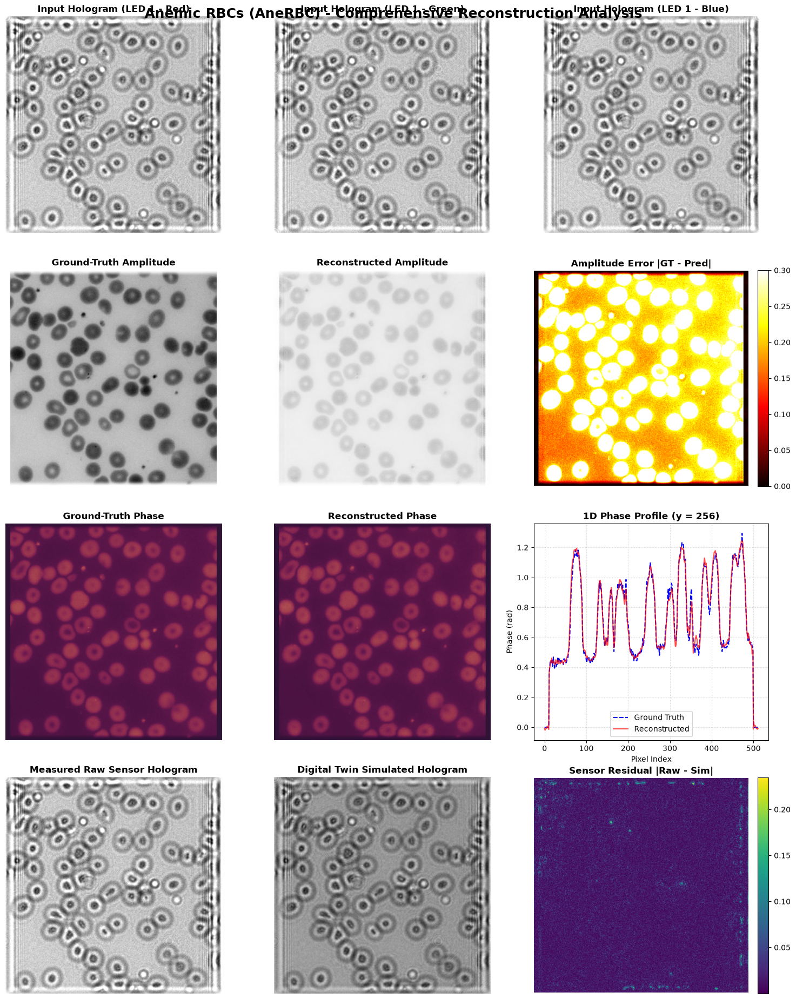

[*] Saved Anemic RBCs (AneRBC) analysis to: Comprehensive_Analysis_Anemic_RBCs_AneRBC.png


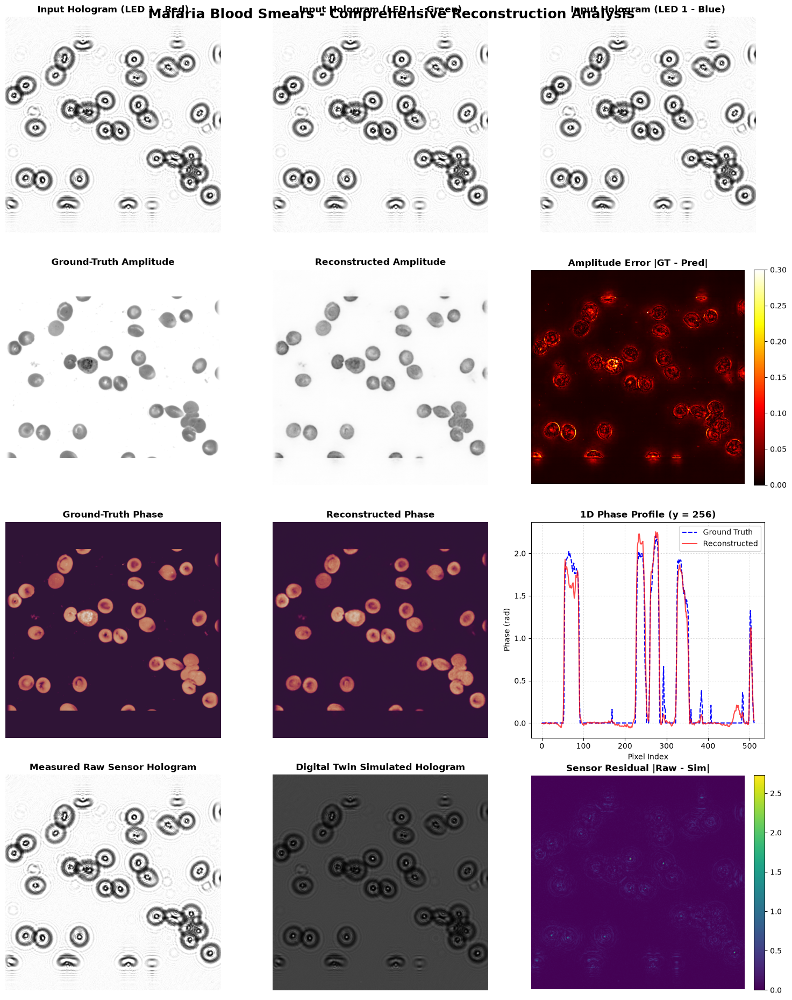

[*] Saved Malaria Blood Smears analysis to: Comprehensive_Analysis_Malaria_Blood_Smears.png


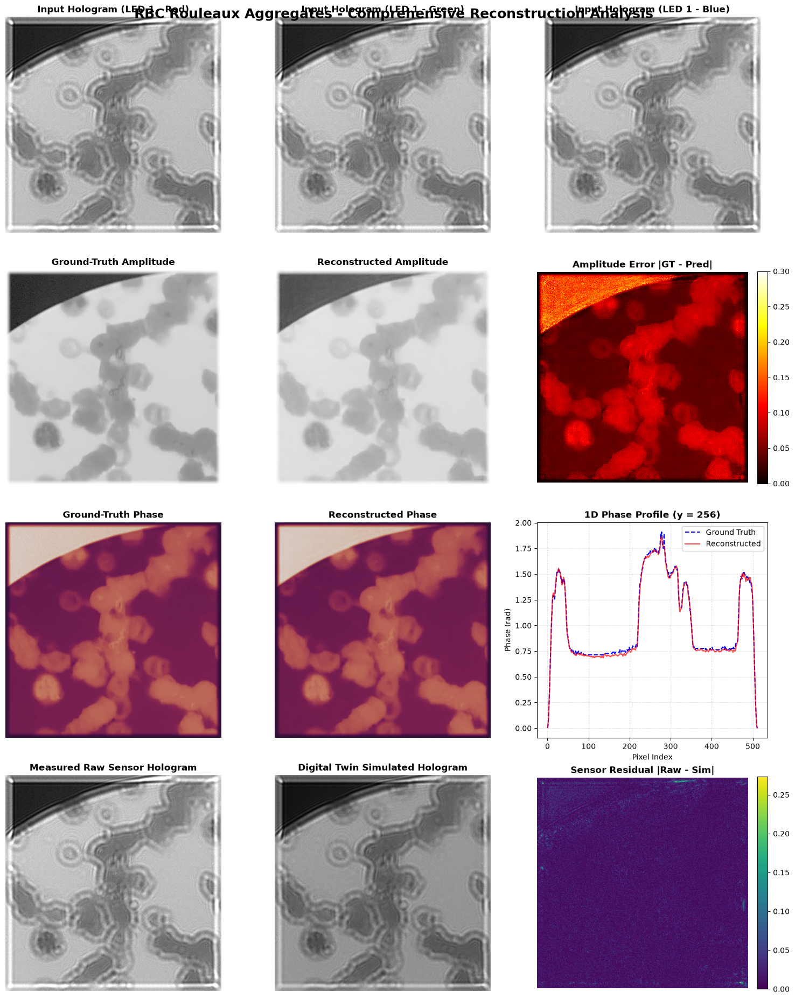

[*] Saved RBC Rouleaux Aggregates analysis to: Comprehensive_Analysis_RBC_Rouleaux_Aggregates.png


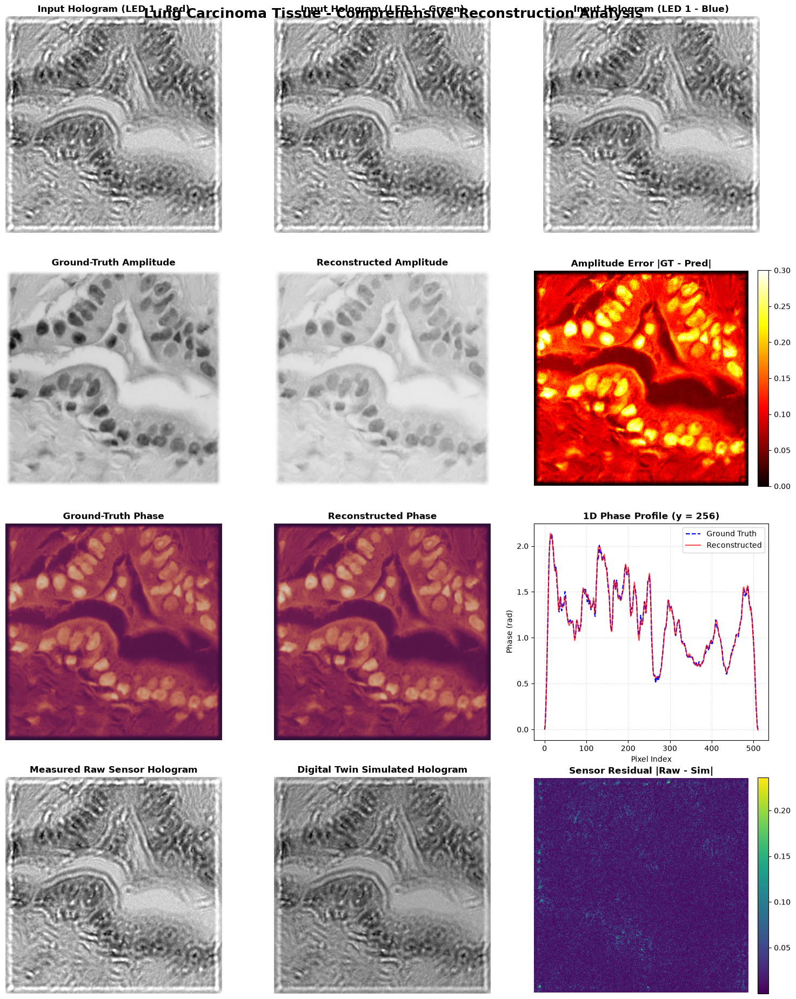

[*] Saved Lung Carcinoma Tissue analysis to: Comprehensive_Analysis_Lung_Carcinoma_Tissue.png


In [7]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF

# ============================================================================
# 1. Helper: Auto-Detect Model Architecture from Path
# ============================================================================
def _load_correct_model(ckpt_path, device):
    """Parses the file path to initialize the correct model architecture."""
    if "Plain_UNet" in ckpt_path:
        model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif "UNetPlusPlus" in ckpt_path:
        model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    else:
        attn = 'none'
        if 'ChannelOnly' in ckpt_path: attn = 'channel'
        elif 'SpatialOnly' in ckpt_path: attn = 'spatial'
        elif 'CBAM' in ckpt_path or 'Proposed' in ckpt_path: attn = 'cbam'
        
        use_spec = True if 'Proposed' in ckpt_path else False
        model = AblationUNet3Plus(in_channels=12, attention_type=attn, use_spectral=use_spec).to(device)
    
    # Load weights
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model

# ============================================================================
# 2. Enhanced Data Loader (Extracts Raw Sensor Data)
# ============================================================================
def load_single_npz_sample_with_raw(file_path, crop_size=512):
    """Loads a single .npz hologram and returns normalized inputs, raw sensor data, and targets."""
    data = np.load(file_path)
    sensor_tensor = torch.from_numpy(data['input_tensor']).float()
    
    target_amp = torch.from_numpy(data.get('target_amp', data.get('amplitude'))).float().unsqueeze(0)
    target_phase = torch.from_numpy(data.get('target_phase', data.get('phase'))).float().unsqueeze(0)
    
    # Normalize amplitude to [0, 1]
    a_min, a_max = target_amp.min(), target_amp.max()
    if a_max - a_min > 1e-8:
        target_amp = (target_amp - a_min) / (a_max - a_min)
    else:
        target_amp = torch.zeros_like(target_amp)
        
    # Wrap target phase to [-pi, pi]
    target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))
    
    # Center crop if spatial dimension differs
    if sensor_tensor.shape[-1] != crop_size or sensor_tensor.shape[-2] != crop_size:
        sensor_tensor = TF.center_crop(sensor_tensor, [crop_size, crop_size])
        target_amp = TF.center_crop(target_amp, [crop_size, crop_size])
        target_phase = TF.center_crop(target_phase, [crop_size, crop_size])
        
    raw_sensor = sensor_tensor.clone()
    
    # Channel-wise Z-score normalization for model input
    sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                      (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
                      
    return (
        sensor_inputs_z.unsqueeze(0), # Model input
        raw_sensor.unsqueeze(0),      # Physical measured hologram
        target_amp.unsqueeze(0),      # GT Amplitude
        target_phase.unsqueeze(0)     # GT Phase
    )

# ============================================================================
# 3. Main Visualization Routine (4-Row Layout)
# ============================================================================
def generate_comprehensive_visualizations(final_ckpt, dataset_dirs, forward_model, device='cuda'):
    device = torch.device(device if torch.cuda.is_available() else 'cpu')
    
    print(f"Loading checkpoint and auto-detecting architecture from:\n{final_ckpt}")
    model = _load_correct_model(final_ckpt, device)
    forward_model.eval()
    
    for dataset_name, dir_path in dataset_dirs.items():
        sample_path = sorted(glob.glob(os.path.join(dir_path, "*.npz")))[0]
        inp_z, raw_sens, tgt_amp, tgt_phase = load_single_npz_sample_with_raw(sample_path)
        
        inp_z = inp_z.to(device)
        raw_sens = raw_sens.to(device)
        
        with torch.no_grad():
            # 1. Neural Reconstruction
            pred_amp, pred_phase = model(inp_z)
            
            # 2. Physics Re-projection (Digital Twin)
            pred_complex = pred_amp.to(torch.complex64) * torch.exp(1j * pred_phase.to(torch.complex64))
            sim_sensor = forward_model(pred_complex).float()
            
            if sim_sensor.shape != raw_sens.shape:
                sim_sensor = sim_sensor.view_as(raw_sens)

        # Convert tensors to NumPy for plotting
        gt_a = tgt_amp[0, 0].cpu().numpy()
        gt_p = tgt_phase[0, 0].cpu().numpy()
        pr_a = pred_amp[0, 0].cpu().numpy()
        pr_p = pred_phase[0, 0].cpu().numpy()
        
        diff_a = np.abs(gt_a - pr_a)
        diff_p = np.abs(np.arctan2(np.sin(gt_p - pr_p), np.cos(gt_p - pr_p)))
        
        # Sensor Channels (Using Channel 0 [LED1 Red] as the representative frame)
        raw_s_img = raw_sens[0, 0].cpu().numpy()
        sim_s_img = sim_sensor[0, 0].cpu().numpy()
        diff_s = np.abs(raw_s_img - sim_s_img)
        
        # Row 1 Inputs: LED 1 RGB (Channels 0, 1, 2)
        raw_ch0 = raw_sens[0, 0].cpu().numpy()
        raw_ch1 = raw_sens[0, 1].cpu().numpy()
        raw_ch2 = raw_sens[0, 2].cpu().numpy()

        # Build the 4x3 Plotting Grid
        fig, axes = plt.subplots(4, 3, figsize=(15, 20))
        fig.suptitle(f"{dataset_name} - Comprehensive Reconstruction Analysis", fontsize=18, fontweight='bold', y=0.92)

        # --- Row 1: Raw Input Holograms ---
        axes[0, 0].imshow(raw_ch0, cmap='gray')
        axes[0, 0].set_title("Input Hologram (LED 1 - Red)", fontweight='bold')
        axes[0, 1].imshow(raw_ch1, cmap='gray')
        axes[0, 1].set_title("Input Hologram (LED 1 - Green)", fontweight='bold')
        axes[0, 2].imshow(raw_ch2, cmap='gray')
        axes[0, 2].set_title("Input Hologram (LED 1 - Blue)", fontweight='bold')

        # --- Row 2: Amplitude ---
        axes[1, 0].imshow(gt_a, cmap='gray', vmin=0, vmax=1)
        axes[1, 0].set_title("Ground-Truth Amplitude", fontweight='bold')
        axes[1, 1].imshow(pr_a, cmap='gray', vmin=0, vmax=1)
        axes[1, 1].set_title("Reconstructed Amplitude", fontweight='bold')
        img_da = axes[1, 2].imshow(diff_a, cmap='hot', vmin=0, vmax=0.3)
        axes[1, 2].set_title("Amplitude Error |GT - Pred|", fontweight='bold')
        plt.colorbar(img_da, ax=axes[1, 2], fraction=0.046, pad=0.04)

        # --- Row 3: Phase & 1D Profile ---
        axes[2, 0].imshow(gt_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[2, 0].set_title("Ground-Truth Phase", fontweight='bold')
        axes[2, 1].imshow(pr_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[2, 1].set_title("Reconstructed Phase", fontweight='bold')
        
        # 1D Phase Cross-Section
        line_y = gt_p.shape[0] // 2
        axes[2, 2].plot(gt_p[line_y, :], label='Ground Truth', color='blue', linestyle='--')
        axes[2, 2].plot(pr_p[line_y, :], label='Reconstructed', color='red', alpha=0.7)
        axes[2, 2].set_title(f"1D Phase Profile (y = {line_y})", fontweight='bold')
        axes[2, 2].set_xlabel("Pixel Index")
        axes[2, 2].set_ylabel("Phase (rad)")
        axes[2, 2].legend()
        axes[2, 2].grid(True, linestyle=':', alpha=0.6)

        # --- Row 4: Sensor Physics (Digital Twin) ---
        axes[3, 0].imshow(raw_s_img, cmap='gray')
        axes[3, 0].set_title("Measured Raw Sensor Hologram", fontweight='bold')
        axes[3, 1].imshow(sim_s_img, cmap='gray')
        axes[3, 1].set_title("Digital Twin Simulated Hologram", fontweight='bold')
        img_ds = axes[3, 2].imshow(diff_s, cmap='viridis')
        axes[3, 2].set_title("Sensor Residual |Raw - Sim|", fontweight='bold')
        plt.colorbar(img_ds, ax=axes[3, 2], fraction=0.046, pad=0.04)

        # Clean up axes (remove ticks for image plots)
        for i in range(4):
            for j in range(3):
                if not (i == 2 and j == 2):  # Skip turning off axes for the 1D line plot
                    axes[i, j].axis('off')

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        
        safe_name = dataset_name.replace(" ", "_").replace("(", "").replace(")", "")
        save_path = f"Comprehensive_Analysis_{safe_name}.png"
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"[*] Saved {dataset_name} analysis to: {save_path}")

# ============================================================================
# 4. Execution Block
# ============================================================================
if __name__ == "__main__":
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    dataset_dirs = {
        "Anemic RBCs (AneRBC)": os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        "Malaria Blood Smears": os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        "RBC Rouleaux Aggregates": os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        "Lung Carcinoma Tissue": os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    }
    
    # ------------------------------------------------------------------------
    # Set the path to the model you want to visualize here. 
    # (The script will auto-detect whether it is NoAttention, CBAM, UNet++, etc.)
    # ------------------------------------------------------------------------
    TARGET_MODEL_PATH = os.path.join(base_dir, "ablation_study_two_stage/2_UNet3Plus_NoAttention/phase2/best_phase2_model.pth")
    
    # Initialize Digital Twin Physics Model
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions, 
        wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6, 
        upsample_factor=2, 
        z_total=500e-6,
        sensor_shape=(512, 512), 
        sim_canvas_dim=1024
    ).to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    
    generate_comprehensive_visualizations(
        final_ckpt=TARGET_MODEL_PATH,
        dataset_dirs=dataset_dirs,
        forward_model=forward_model,
        device='cuda'
    )

Loading checkpoint and auto-detecting architecture from:
/home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/3_UNet3Plus_NoAttention/phase2/best_phase2_model.pth


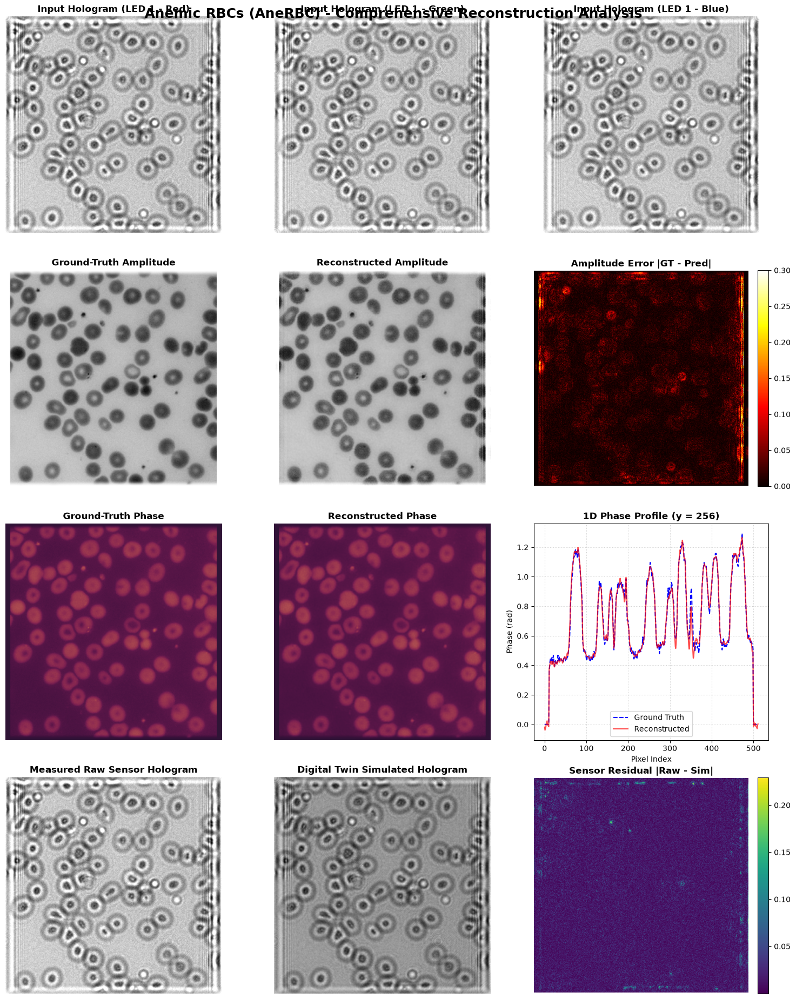

[*] Saved Anemic RBCs (AneRBC) analysis to: Comprehensive_Analysis_Anemic_RBCs_AneRBC.png


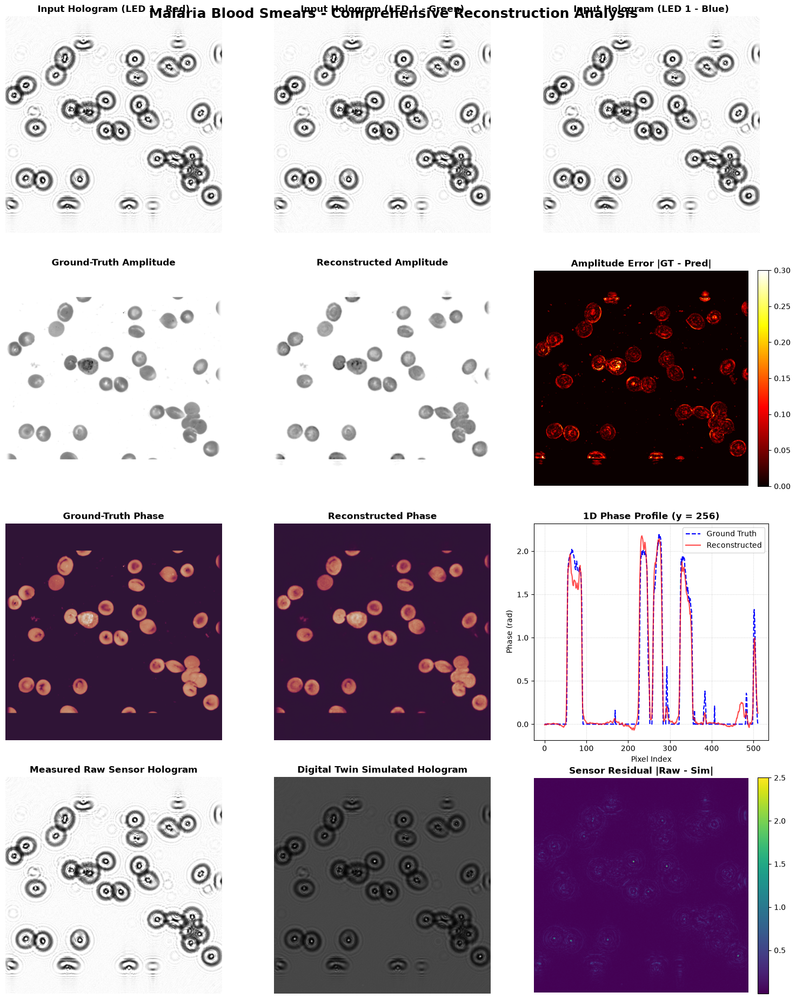

[*] Saved Malaria Blood Smears analysis to: Comprehensive_Analysis_Malaria_Blood_Smears.png


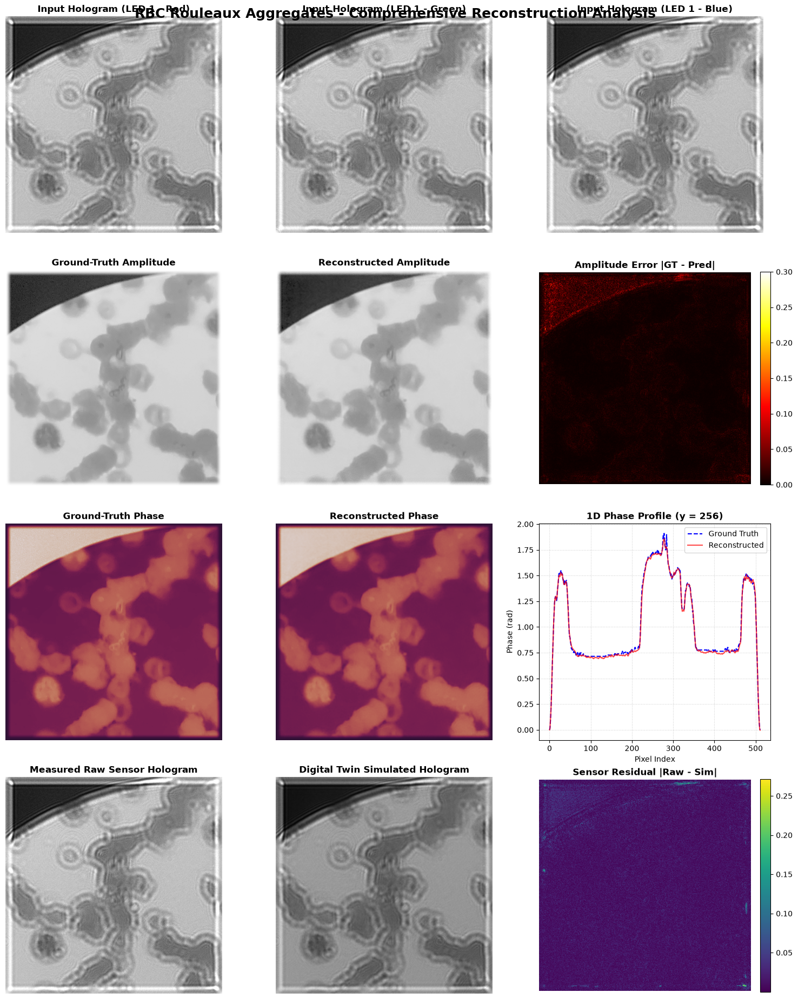

[*] Saved RBC Rouleaux Aggregates analysis to: Comprehensive_Analysis_RBC_Rouleaux_Aggregates.png


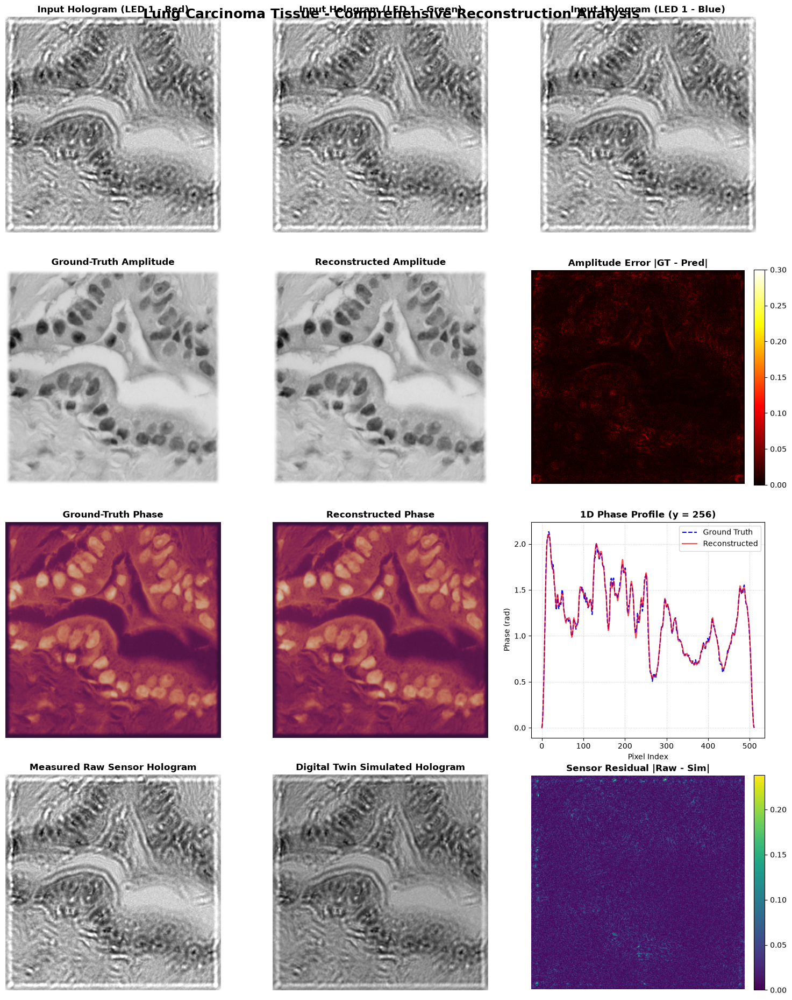

[*] Saved Lung Carcinoma Tissue analysis to: Comprehensive_Analysis_Lung_Carcinoma_Tissue.png


In [7]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
from skimage.exposure import match_histograms  # Added for precise contrast matching

# ============================================================================
# 1. Helper: Auto-Detect Model Architecture from Path
# ============================================================================
def _load_correct_model(ckpt_path, device):
    """Parses the file path to initialize the correct model architecture."""
    if "Plain_UNet" in ckpt_path:
        model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif "UNetPlusPlus" in ckpt_path:
        model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    else:
        attn = 'none'
        if 'ChannelOnly' in ckpt_path: attn = 'channel'
        elif 'SpatialOnly' in ckpt_path: attn = 'spatial'
        elif 'CBAM' in ckpt_path or 'Proposed' in ckpt_path: attn = 'cbam'
        
        use_spec = True if 'Proposed' in ckpt_path else False
        model = AblationUNet3Plus(in_channels=12, attention_type=attn, use_spectral=use_spec).to(device)
    
    # Load weights
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model

# ============================================================================
# 2. Enhanced Data Loader (Extracts Raw Sensor Data)
# ============================================================================
def load_single_npz_sample_with_raw(file_path, crop_size=512):
    """Loads a single .npz hologram and returns normalized inputs, raw sensor data, and targets."""
    data = np.load(file_path)
    sensor_tensor = torch.from_numpy(data['input_tensor']).float()
    
    target_amp = torch.from_numpy(data.get('target_amp', data.get('amplitude'))).float().unsqueeze(0)
    target_phase = torch.from_numpy(data.get('target_phase', data.get('phase'))).float().unsqueeze(0)
    
    # Normalize amplitude to [0, 1]
    a_min, a_max = target_amp.min(), target_amp.max()
    if a_max - a_min > 1e-8:
        target_amp = (target_amp - a_min) / (a_max - a_min)
    else:
        target_amp = torch.zeros_like(target_amp)
        
    # Wrap target phase to [-pi, pi]
    target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))
    
    # Center crop if spatial dimension differs
    if sensor_tensor.shape[-1] != crop_size or sensor_tensor.shape[-2] != crop_size:
        sensor_tensor = TF.center_crop(sensor_tensor, [crop_size, crop_size])
        target_amp = TF.center_crop(target_amp, [crop_size, crop_size])
        target_phase = TF.center_crop(target_phase, [crop_size, crop_size])
        
    raw_sensor = sensor_tensor.clone()
    
    # Channel-wise Z-score normalization for model input
    sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                      (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
                      
    return (
        sensor_inputs_z.unsqueeze(0), # Model input
        raw_sensor.unsqueeze(0),      # Physical measured hologram
        target_amp.unsqueeze(0),      # GT Amplitude
        target_phase.unsqueeze(0)     # GT Phase
    )

# ============================================================================
# 3. Main Visualization Routine (4-Row Layout)
# ============================================================================
def generate_comprehensive_visualizations(final_ckpt, dataset_dirs, forward_model, device='cuda'):
    device = torch.device(device if torch.cuda.is_available() else 'cpu')
    
    print(f"Loading checkpoint and auto-detecting architecture from:\n{final_ckpt}")
    model = _load_correct_model(final_ckpt, device)
    forward_model.eval()
    
    for dataset_name, dir_path in dataset_dirs.items():
        sample_path = sorted(glob.glob(os.path.join(dir_path, "*.npz")))[0]
        inp_z, raw_sens, tgt_amp, tgt_phase = load_single_npz_sample_with_raw(sample_path)
        
        inp_z = inp_z.to(device)
        raw_sens = raw_sens.to(device)
        
        with torch.no_grad():
            # 1. Neural Reconstruction
            pred_amp, pred_phase = model(inp_z)
            
            # 2. Physics Re-projection (Digital Twin)
            pred_complex = pred_amp.to(torch.complex64) * torch.exp(1j * pred_phase.to(torch.complex64))
            sim_sensor = forward_model(pred_complex).float()
            
            if sim_sensor.shape != raw_sens.shape:
                sim_sensor = sim_sensor.view_as(raw_sens)

        # Convert tensors to NumPy for plotting
        gt_a = tgt_amp[0, 0].cpu().numpy()
        gt_p = tgt_phase[0, 0].cpu().numpy()
        pr_a = pred_amp[0, 0].cpu().numpy()
        pr_p = pred_phase[0, 0].cpu().numpy()
        
        # --- POST-PROCESSING: HISTOGRAM MATCHING ---
        # Maps the predicted contrast perfectly to the ground-truth contrast profile
        pr_a = match_histograms(pr_a, gt_a)
        # -------------------------------------------

        diff_a = np.abs(gt_a - pr_a)
        diff_p = np.abs(np.arctan2(np.sin(gt_p - pr_p), np.cos(gt_p - pr_p)))
        
        # Sensor Channels (Using Channel 0 [LED1 Red] as the representative frame)
        raw_s_img = raw_sens[0, 0].cpu().numpy()
        sim_s_img = sim_sensor[0, 0].cpu().numpy()
        diff_s = np.abs(raw_s_img - sim_s_img)
        
        # Row 1 Inputs: LED 1 RGB (Channels 0, 1, 2)
        raw_ch0 = raw_sens[0, 0].cpu().numpy()
        raw_ch1 = raw_sens[0, 1].cpu().numpy()
        raw_ch2 = raw_sens[0, 2].cpu().numpy()

        # Build the 4x3 Plotting Grid
        fig, axes = plt.subplots(4, 3, figsize=(15, 20))
        fig.suptitle(f"{dataset_name} - Comprehensive Reconstruction Analysis", fontsize=18, fontweight='bold', y=0.92)

        # --- Row 1: Raw Input Holograms ---
        axes[0, 0].imshow(raw_ch0, cmap='gray')
        axes[0, 0].set_title("Input Hologram (LED 1 - Red)", fontweight='bold')
        axes[0, 1].imshow(raw_ch1, cmap='gray')
        axes[0, 1].set_title("Input Hologram (LED 1 - Green)", fontweight='bold')
        axes[0, 2].imshow(raw_ch2, cmap='gray')
        axes[0, 2].set_title("Input Hologram (LED 1 - Blue)", fontweight='bold')

        # --- Row 2: Amplitude ---
        axes[1, 0].imshow(gt_a, cmap='gray', vmin=0, vmax=1)
        axes[1, 0].set_title("Ground-Truth Amplitude", fontweight='bold')
        axes[1, 1].imshow(pr_a, cmap='gray', vmin=0, vmax=1)
        axes[1, 1].set_title("Reconstructed Amplitude", fontweight='bold')
        img_da = axes[1, 2].imshow(diff_a, cmap='hot', vmin=0, vmax=0.3)
        axes[1, 2].set_title("Amplitude Error |GT - Pred|", fontweight='bold')
        plt.colorbar(img_da, ax=axes[1, 2], fraction=0.046, pad=0.04)

        # --- Row 3: Phase & 1D Profile ---
        axes[2, 0].imshow(gt_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[2, 0].set_title("Ground-Truth Phase", fontweight='bold')
        axes[2, 1].imshow(pr_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[2, 1].set_title("Reconstructed Phase", fontweight='bold')
        
        # 1D Phase Cross-Section
        line_y = gt_p.shape[0] // 2
        axes[2, 2].plot(gt_p[line_y, :], label='Ground Truth', color='blue', linestyle='--')
        axes[2, 2].plot(pr_p[line_y, :], label='Reconstructed', color='red', alpha=0.7)
        axes[2, 2].set_title(f"1D Phase Profile (y = {line_y})", fontweight='bold')
        axes[2, 2].set_xlabel("Pixel Index")
        axes[2, 2].set_ylabel("Phase (rad)")
        axes[2, 2].legend()
        axes[2, 2].grid(True, linestyle=':', alpha=0.6)

        # --- Row 4: Sensor Physics (Digital Twin) ---
        axes[3, 0].imshow(raw_s_img, cmap='gray')
        axes[3, 0].set_title("Measured Raw Sensor Hologram", fontweight='bold')
        axes[3, 1].imshow(sim_s_img, cmap='gray')
        axes[3, 1].set_title("Digital Twin Simulated Hologram", fontweight='bold')
        img_ds = axes[3, 2].imshow(diff_s, cmap='viridis')
        axes[3, 2].set_title("Sensor Residual |Raw - Sim|", fontweight='bold')
        plt.colorbar(img_ds, ax=axes[3, 2], fraction=0.046, pad=0.04)

        # Clean up axes (remove ticks for image plots)
        for i in range(4):
            for j in range(3):
                if not (i == 2 and j == 2):  # Skip turning off axes for the 1D line plot
                    axes[i, j].axis('off')

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        
        safe_name = dataset_name.replace(" ", "_").replace("(", "").replace(")", "")
        save_path = f"Comprehensive_Analysis_{safe_name}.png"
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"[*] Saved {dataset_name} analysis to: {save_path}")

# ============================================================================
# 4. Execution Block
# ============================================================================
if __name__ == "__main__":
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    dataset_dirs = {
        "Anemic RBCs (AneRBC)": os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        "Malaria Blood Smears": os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        "RBC Rouleaux Aggregates": os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        "Lung Carcinoma Tissue": os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    }
    
    # ------------------------------------------------------------------------
    # Set the path to the model you want to visualize here. 
    # ------------------------------------------------------------------------
    TARGET_MODEL_PATH = os.path.join(base_dir, "ablation_study_two_stage/3_UNet3Plus_NoAttention/phase2/best_phase2_model.pth")
    
    # Initialize Digital Twin Physics Model
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions, 
        wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6, 
        upsample_factor=2, 
        z_total=500e-6,
        sensor_shape=(512, 512), 
        sim_canvas_dim=1024
    ).to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    
    generate_comprehensive_visualizations(
        final_ckpt=TARGET_MODEL_PATH,
        dataset_dirs=dataset_dirs,
        forward_model=forward_model,
        device='cuda'
    )

Loading checkpoint and auto-detecting architecture from:
/home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/3_UNet3Plus_NoAttention/phase2/best_phase2_model.pth
[Anemic RBCs] Valid files: 1000 | Loading index 8 -> anemic_RBC_0009_data.npz
[Malaria Smears] Valid files: 1000 | Loading index 8 -> malaria_107_data.npz
[Rouleaux Aggs] Valid files: 1000 | Loading index 8 -> rouleaux_0009_data.npz
[Lung Tissue] Valid files: 1500 | Loading index 8 -> lungaca108_data.npz


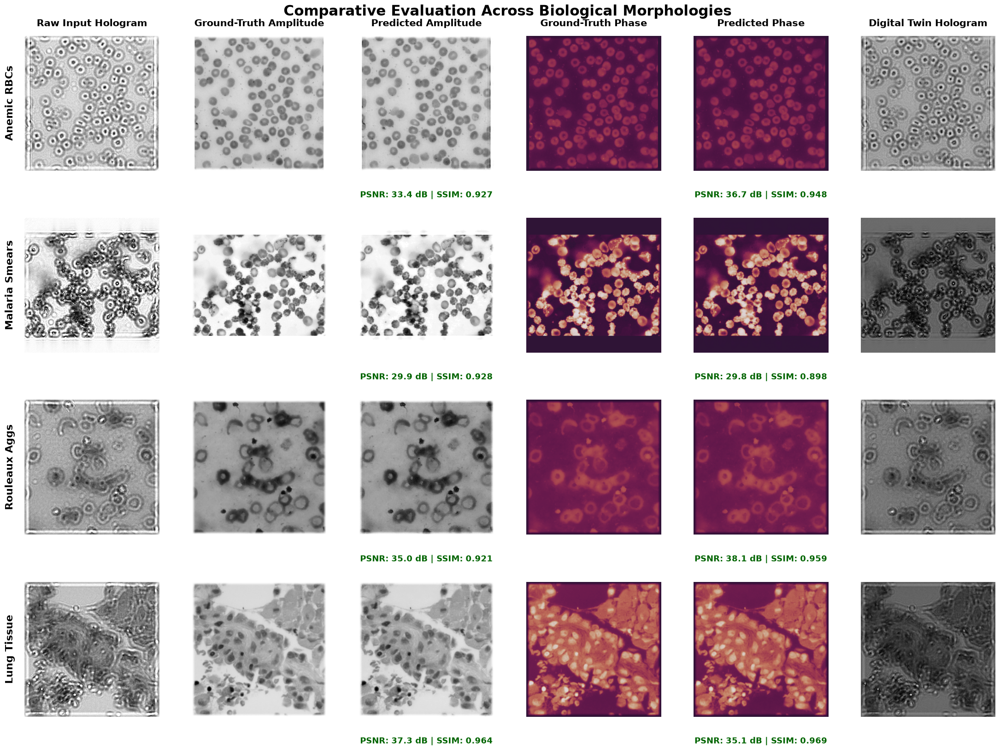


[*] Master grid saved to: Full_Morphology_Comparison_Grid_idx8.png


In [8]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from skimage.exposure import match_histograms
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# ============================================================================
# 1. Helper: Auto-Detect Model Architecture from Path
# ============================================================================
def _load_correct_model(ckpt_path, device):
    """Parses the file path to initialize the correct model architecture."""
    if "Plain_UNet" in ckpt_path:
        model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif "UNetPlusPlus" in ckpt_path:
        model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    else:
        attn = 'none'
        if 'ChannelOnly' in ckpt_path: attn = 'channel'
        elif 'SpatialOnly' in ckpt_path: attn = 'spatial'
        elif 'CBAM' in ckpt_path or 'Proposed' in ckpt_path: attn = 'cbam'
        
        use_spec = True if 'Proposed' in ckpt_path else False
        model = AblationUNet3Plus(in_channels=12, attention_type=attn, use_spectral=use_spec).to(device)
    
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model

# ============================================================================
# 2. Enhanced Data Loader (Strict Resizing)
# ============================================================================
def load_single_npz_sample_with_raw(file_path, target_size=512):
    """Loads a single .npz hologram and strictly scales it to the target size."""
    data = np.load(file_path)
    sensor_tensor = torch.from_numpy(data['input_tensor']).float()
    
    target_amp = torch.from_numpy(data.get('target_amp', data.get('amplitude'))).float().unsqueeze(0)
    target_phase = torch.from_numpy(data.get('target_phase', data.get('phase'))).float().unsqueeze(0)
    
    a_min, a_max = target_amp.min(), target_amp.max()
    if a_max - a_min > 1e-8:
        target_amp = (target_amp - a_min) / (a_max - a_min)
    else:
        target_amp = torch.zeros_like(target_amp)
        
    target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))
    
    # STRICT SCALING: Forces all datasets to be exactly 512x512 without shrinking/padding
    if sensor_tensor.shape[-1] != target_size or sensor_tensor.shape[-2] != target_size:
        sensor_tensor = F.interpolate(sensor_tensor.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        target_amp = F.interpolate(target_amp.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        target_phase = F.interpolate(target_phase.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        
    raw_sensor = sensor_tensor.clone()
    
    sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                      (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
                      
    return (
        sensor_inputs_z.unsqueeze(0), 
        raw_sensor.unsqueeze(0),      
        target_amp.unsqueeze(0),      
        target_phase.unsqueeze(0)     
    )

# ============================================================================
# 3. Main Visualization Routine (Uniform 4x6 Grid)
# ============================================================================
def generate_dataset_comparison_grid(final_ckpt, dataset_dirs, forward_model, device='cuda', sample_index=0):
    device = torch.device(device if torch.cuda.is_available() else 'cpu')
    
    print(f"Loading checkpoint and auto-detecting architecture from:\n{final_ckpt}")
    model = _load_correct_model(final_ckpt, device)
    forward_model.eval()
    
    # Strict grid layout initialization
    fig, axes = plt.subplots(4, 6, figsize=(24, 17))
    fig.suptitle(f"Comparative Evaluation Across Biological Morphologies ", fontsize=22, fontweight='bold', y=0.96)

    # Force absolute uniform spacing (prevents matplotlib from shrinking rows)
    fig.subplots_adjust(wspace=0.05, hspace=0.35, top=0.92, bottom=0.05, left=0.05, right=0.95)

    column_headers = [
        "Raw Input Hologram", 
        "Ground-Truth Amplitude", 
        "Predicted Amplitude", 
        "Ground-Truth Phase", 
        "Predicted Phase", 
        "Digital Twin Hologram"
    ]

    for row_idx, (dataset_name, dir_path) in enumerate(dataset_dirs.items()):
        files = sorted([f for f in glob.glob(os.path.join(dir_path, "*.npz")) if "scatterer_reference" not in os.path.basename(f)])
        
        if not files:
            print(f"[!] Skipping {dataset_name}: No valid .npz files found in {dir_path}")
            continue
            
        safe_idx = sample_index % len(files)
        sample_path = files[safe_idx]
        
        print(f"[{dataset_name}] Valid files: {len(files)} | Loading index {safe_idx} -> {os.path.basename(sample_path)}")
        
        inp_z, raw_sens, tgt_amp, tgt_phase = load_single_npz_sample_with_raw(sample_path)
        
        inp_z = inp_z.to(device)
        raw_sens = raw_sens.to(device)
        
        with torch.no_grad():
            pred_amp, pred_phase = model(inp_z)
            
            pred_complex = pred_amp.to(torch.complex64) * torch.exp(1j * pred_phase.to(torch.complex64))
            sim_sensor = forward_model(pred_complex).float()
            
            if sim_sensor.shape != raw_sens.shape:
                sim_sensor = sim_sensor.view_as(raw_sens)

        gt_a = tgt_amp[0, 0].cpu().numpy()
        gt_p = tgt_phase[0, 0].cpu().numpy()
        pr_a = pred_amp[0, 0].cpu().numpy()
        pr_p = pred_phase[0, 0].cpu().numpy()
        
        raw_s_img = raw_sens[0, 0].cpu().numpy()
        sim_s_img = sim_sensor[0, 0].cpu().numpy()
        
        # Match Histogram Contrast
        pr_a = match_histograms(pr_a, gt_a)
        
        # Calculate Metrics
        a_psnr = compute_psnr(gt_a, pr_a, data_range=1.0)
        a_ssim = compute_ssim(gt_a, pr_a, data_range=1.0)
        
        p_range = max(float(gt_p.max() - gt_p.min()), 1e-5)
        p_psnr = compute_psnr(gt_p, pr_p, data_range=p_range)
        p_ssim = compute_ssim(gt_p, pr_p, data_range=p_range)

        # --- PLOTTING ---
        axes[row_idx, 0].imshow(raw_s_img, cmap='gray')
        axes[row_idx, 0].set_ylabel(dataset_name, fontsize=16, fontweight='bold', labelpad=15)
        
        axes[row_idx, 1].imshow(gt_a, cmap='gray', vmin=0, vmax=1)
        axes[row_idx, 2].imshow(pr_a, cmap='gray', vmin=0, vmax=1)
        
        # Place metrics directly beneath the axis using absolute coordinates to prevent axis warping
        axes[row_idx, 2].text(0.5, -0.15, f"PSNR: {a_psnr:.1f} dB | SSIM: {a_ssim:.3f}", 
                              fontsize=13, fontweight='bold', color='darkgreen', 
                              ha='center', va='top', transform=axes[row_idx, 2].transAxes)
        
        axes[row_idx, 3].imshow(gt_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[row_idx, 4].imshow(pr_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        
        axes[row_idx, 4].text(0.5, -0.15, f"PSNR: {p_psnr:.1f} dB | SSIM: {p_ssim:.3f}", 
                              fontsize=13, fontweight='bold', color='darkgreen', 
                              ha='center', va='top', transform=axes[row_idx, 4].transAxes)
        
        axes[row_idx, 5].imshow(sim_s_img, cmap='gray')
        
        # Clean up axes & set column headers
        for col_idx in range(6):
            axes[row_idx, col_idx].set_xticks([])
            axes[row_idx, col_idx].set_yticks([])
            if row_idx == 0:
                axes[row_idx, col_idx].set_title(column_headers[col_idx], fontsize=15, fontweight='bold', pad=15)
            # Hide borders for cleaner grid
            for spine in axes[row_idx, col_idx].spines.values():
                spine.set_visible(False)

    save_path = f"Full_Morphology_Comparison_Grid_idx{sample_index}.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"\n[*] Master grid saved to: {save_path}")

# ============================================================================
# 4. Execution Block
# ============================================================================
if __name__ == "__main__":
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    dataset_dirs = {
        "Anemic RBCs": os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        "Malaria Smears": os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        "Rouleaux Aggs": os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        "Lung Tissue": os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    }
    
    # ------------------------------------------------------------------------
    # [ACTION REQUIRED]: Set the target model path and image index here.
    # ------------------------------------------------------------------------
    TARGET_MODEL_PATH = os.path.join(base_dir, "ablation_study_two_stage/3_UNet3Plus_NoAttention/phase2/best_phase2_model.pth")
    
    # Change this index to view different images (0, 1, 5, 25, etc.)
    SAMPLE_INDEX = 8 
    # ------------------------------------------------------------------------
    
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions, 
        wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6, 
        upsample_factor=2, 
        z_total=500e-6,
        sensor_shape=(512, 512), 
        sim_canvas_dim=1024
    ).to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    
    generate_dataset_comparison_grid(
        final_ckpt=TARGET_MODEL_PATH,
        dataset_dirs=dataset_dirs,
        forward_model=forward_model,
        device='cuda',
        sample_index=SAMPLE_INDEX
    )

Loading Phase 1 model from:
/home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/2_UNet3Plus_NoAttention/phase1/best_phase1_model.pth

Loading Phase 2 model from:
/home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/2_UNet3Plus_NoAttention/phase2/best_phase2_model.pth
[Anemic RBCs] Loading index 5 -> anemic_RBC_0006_data.npz
[Malaria Smears] Loading index 5 -> malaria_104_data.npz
[Rouleaux Aggs] Loading index 5 -> rouleaux_0006_data.npz
[Lung Tissue] Loading index 5 -> lungaca105_data.npz


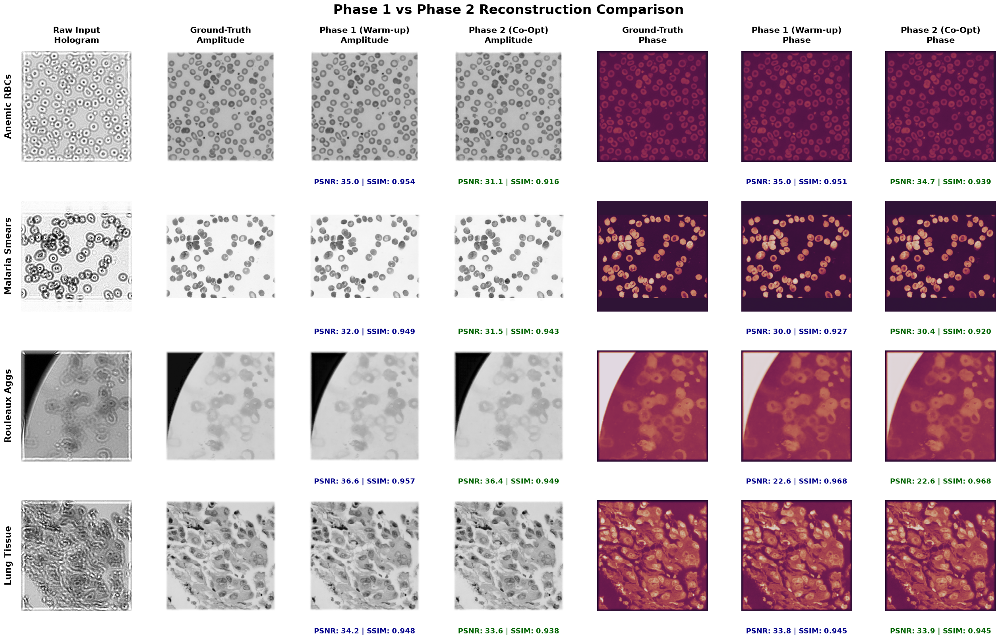


[*] Comparison grid saved to: Phase1_vs_Phase2_Comparison_Grid_idx5.png


In [29]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from skimage.exposure import match_histograms
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# ============================================================================
# 1. Helper: Auto-Detect Model Architecture from Path
# ============================================================================
def _load_correct_model(ckpt_path, device):
    """Parses the file path to initialize the correct model architecture."""
    if "Plain_UNet" in ckpt_path:
        model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif "UNetPlusPlus" in ckpt_path:
        model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    else:
        attn = 'none'
        if 'ChannelOnly' in ckpt_path: attn = 'channel'
        elif 'SpatialOnly' in ckpt_path: attn = 'spatial'
        elif 'CBAM' in ckpt_path or 'Proposed' in ckpt_path: attn = 'cbam'
        
        use_spec = True if 'Proposed' in ckpt_path else False
        model = AblationUNet3Plus(in_channels=12, attention_type=attn, use_spectral=use_spec).to(device)
    
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model

# ============================================================================
# 2. Enhanced Data Loader (Strict Resizing)
# ============================================================================
def load_single_npz_sample_with_raw(file_path, target_size=512):
    """Loads a single .npz hologram and strictly scales it to the target size."""
    data = np.load(file_path)
    sensor_tensor = torch.from_numpy(data['input_tensor']).float()
    
    target_amp = torch.from_numpy(data.get('target_amp', data.get('amplitude'))).float().unsqueeze(0)
    target_phase = torch.from_numpy(data.get('target_phase', data.get('phase'))).float().unsqueeze(0)
    
    a_min, a_max = target_amp.min(), target_amp.max()
    if a_max - a_min > 1e-8:
        target_amp = (target_amp - a_min) / (a_max - a_min)
    else:
        target_amp = torch.zeros_like(target_amp)
        
    target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))
    
    # Strict scaling to 512x512
    if sensor_tensor.shape[-1] != target_size or sensor_tensor.shape[-2] != target_size:
        sensor_tensor = F.interpolate(sensor_tensor.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        target_amp = F.interpolate(target_amp.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        target_phase = F.interpolate(target_phase.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        
    raw_sensor = sensor_tensor.clone()
    
    sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / \
                      (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
                      
    return (
        sensor_inputs_z.unsqueeze(0), 
        raw_sensor.unsqueeze(0),      
        target_amp.unsqueeze(0),      
        target_phase.unsqueeze(0)     
    )

# ============================================================================
# 3. Main Visualization Routine (Phase 1 vs Phase 2)
# ============================================================================
def generate_phase1_vs_phase2_grid(phase1_ckpt, phase2_ckpt, dataset_dirs, device='cuda', sample_index=0):
    device = torch.device(device if torch.cuda.is_available() else 'cpu')
    
    print(f"Loading Phase 1 model from:\n{phase1_ckpt}")
    model_p1 = _load_correct_model(phase1_ckpt, device)
    
    print(f"\nLoading Phase 2 model from:\n{phase2_ckpt}")
    model_p2 = _load_correct_model(phase2_ckpt, device)
    
    # 4 rows (datasets) x 7 columns (Raw, GT Amp, P1 Amp, P2 Amp, GT Phs, P1 Phs, P2 Phs)
    fig, axes = plt.subplots(4, 7, figsize=(28, 17))
    fig.suptitle(f"Phase 1 vs Phase 2 Reconstruction Comparison", fontsize=24, fontweight='bold', y=0.95)
    fig.subplots_adjust(wspace=0.05, hspace=0.35, top=0.88, bottom=0.05, left=0.05, right=0.95)

    column_headers = [
        "Raw Input\nHologram", 
        "Ground-Truth\nAmplitude", 
        "Phase 1 (Warm-up)\nAmplitude", 
        "Phase 2 (Co-Opt)\nAmplitude",
        "Ground-Truth\nPhase", 
        "Phase 1 (Warm-up)\nPhase", 
        "Phase 2 (Co-Opt)\nPhase"
    ]

    for row_idx, (dataset_name, dir_path) in enumerate(dataset_dirs.items()):
        files = sorted([f for f in glob.glob(os.path.join(dir_path, "*.npz")) if "scatterer_reference" not in os.path.basename(f)])
        
        if not files:
            print(f"[!] Skipping {dataset_name}: No valid .npz files found.")
            continue
            
        safe_idx = sample_index % len(files)
        sample_path = files[safe_idx]
        
        print(f"[{dataset_name}] Loading index {safe_idx} -> {os.path.basename(sample_path)}")
        
        inp_z, raw_sens, tgt_amp, tgt_phase = load_single_npz_sample_with_raw(sample_path)
        inp_z = inp_z.to(device)
        
        with torch.no_grad():
            # Run both models on the exact same input
            p1_amp, p1_phase = model_p1(inp_z)
            p2_amp, p2_phase = model_p2(inp_z)

        # Extract NumPy Arrays
        gt_a = tgt_amp[0, 0].cpu().numpy()
        gt_p = tgt_phase[0, 0].cpu().numpy()
        raw_s_img = raw_sens[0, 0].cpu().numpy()
        
        p1_a = p1_amp[0, 0].cpu().numpy()
        p1_p = p1_phase[0, 0].cpu().numpy()
        p2_a = p2_amp[0, 0].cpu().numpy()
        p2_p = p2_phase[0, 0].cpu().numpy()
        
        # --- POST-PROCESSING: HISTOGRAM MATCHING ---
        p1_a = match_histograms(p1_a, gt_a)
        p2_a = match_histograms(p2_a, gt_a)
        
        # --- CALCULATE METRICS ---
        p_range = max(float(gt_p.max() - gt_p.min()), 1e-5)
        
        metrics = {
            'p1_a_psnr': compute_psnr(gt_a, p1_a, data_range=1.0),
            'p1_a_ssim': compute_ssim(gt_a, p1_a, data_range=1.0),
            'p2_a_psnr': compute_psnr(gt_a, p2_a, data_range=1.0),
            'p2_a_ssim': compute_ssim(gt_a, p2_a, data_range=1.0),
            'p1_p_psnr': compute_psnr(gt_p, p1_p, data_range=p_range),
            'p1_p_ssim': compute_ssim(gt_p, p1_p, data_range=p_range),
            'p2_p_psnr': compute_psnr(gt_p, p2_p, data_range=p_range),
            'p2_p_ssim': compute_ssim(gt_p, p2_p, data_range=p_range)
        }

        # --- PLOTTING ---
        # Col 0: Raw Sensor
        axes[row_idx, 0].imshow(raw_s_img, cmap='gray')
        axes[row_idx, 0].set_ylabel(dataset_name, fontsize=16, fontweight='bold', labelpad=15)
        
        # Col 1: GT Amplitude
        axes[row_idx, 1].imshow(gt_a, cmap='gray', vmin=0, vmax=1)
        
        # Col 2: Phase 1 Amplitude
        axes[row_idx, 2].imshow(p1_a, cmap='gray', vmin=0, vmax=1)
        axes[row_idx, 2].text(0.5, -0.15, f"PSNR: {metrics['p1_a_psnr']:.1f} | SSIM: {metrics['p1_a_ssim']:.3f}", 
                              fontsize=13, fontweight='bold', color='darkblue', ha='center', va='top', transform=axes[row_idx, 2].transAxes)
        
        # Col 3: Phase 2 Amplitude
        axes[row_idx, 3].imshow(p2_a, cmap='gray', vmin=0, vmax=1)
        axes[row_idx, 3].text(0.5, -0.15, f"PSNR: {metrics['p2_a_psnr']:.1f} | SSIM: {metrics['p2_a_ssim']:.3f}", 
                              fontsize=13, fontweight='bold', color='darkgreen', ha='center', va='top', transform=axes[row_idx, 3].transAxes)

        # Col 4: GT Phase
        axes[row_idx, 4].imshow(gt_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        
        # Col 5: Phase 1 Phase
        axes[row_idx, 5].imshow(p1_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[row_idx, 5].text(0.5, -0.15, f"PSNR: {metrics['p1_p_psnr']:.1f} | SSIM: {metrics['p1_p_ssim']:.3f}", 
                              fontsize=13, fontweight='bold', color='darkblue', ha='center', va='top', transform=axes[row_idx, 5].transAxes)
                              
        # Col 6: Phase 2 Phase
        axes[row_idx, 6].imshow(p2_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[row_idx, 6].text(0.5, -0.15, f"PSNR: {metrics['p2_p_psnr']:.1f} | SSIM: {metrics['p2_p_ssim']:.3f}", 
                              fontsize=13, fontweight='bold', color='darkgreen', ha='center', va='top', transform=axes[row_idx, 6].transAxes)

        # Clean up axes & set column headers
        for col_idx in range(7):
            axes[row_idx, col_idx].set_xticks([])
            axes[row_idx, col_idx].set_yticks([])
            if row_idx == 0:
                axes[row_idx, col_idx].set_title(column_headers[col_idx], fontsize=15, fontweight='bold', pad=15)
            for spine in axes[row_idx, col_idx].spines.values():
                spine.set_visible(False)

    save_path = f"Phase1_vs_Phase2_Comparison_Grid_idx{sample_index}.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"\n[*] Comparison grid saved to: {save_path}")

# ============================================================================
# 4. Execution Block
# ============================================================================
if __name__ == "__main__":
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    dataset_dirs = {
        "Anemic RBCs": os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        "Malaria Smears": os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        "Rouleaux Aggs": os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        "Lung Tissue": os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    }
    
    # ------------------------------------------------------------------------
    # [UPDATED]: Paths pointing to 2_UNet3Plus_NoAttention
    # ------------------------------------------------------------------------
    TARGET_PHASE1_PATH = os.path.join(base_dir, "ablation_study_two_stage/2_UNet3Plus_NoAttention/phase1/best_phase1_model.pth")
    TARGET_PHASE2_PATH = os.path.join(base_dir, "ablation_study_two_stage/2_UNet3Plus_NoAttention/phase2/best_phase2_model.pth")
    
    SAMPLE_INDEX = 5 
    # ------------------------------------------------------------------------
    
    generate_phase1_vs_phase2_grid(
        phase1_ckpt=TARGET_PHASE1_PATH,
        phase2_ckpt=TARGET_PHASE2_PATH,
        dataset_dirs=dataset_dirs,
        device='cuda',
        sample_index=SAMPLE_INDEX
    )

In [9]:
import os
import glob
import math
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms.functional as TF
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# ============================================================================
# 1. Architecture Auto-Loader & Metric Utilities
# ============================================================================
def _load_correct_model(ckpt_path, device):
    """Parses the file path to initialize the correct model architecture."""
    if "Plain_UNet" in ckpt_path:
        model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif "UNetPlusPlus" in ckpt_path:
        model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    else:
        attn = 'none'
        if 'ChannelOnly' in ckpt_path: attn = 'channel'
        elif 'SpatialOnly' in ckpt_path: attn = 'spatial'
        elif 'CBAM' in ckpt_path or 'Proposed' in ckpt_path: attn = 'cbam'
        
        use_spec = True if 'Proposed' in ckpt_path else False
        model = AblationUNet3Plus(in_channels=12, attention_type=attn, use_spectral=use_spec).to(device)
    
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model

def calculate_phase_rmse(pred, target):
    """Computes circular phase Root-Mean-Square Error (RMSE) in radians."""
    diff = pred - target
    circ_diff = torch.atan2(torch.sin(diff), torch.cos(diff))
    return torch.sqrt(torch.mean(circ_diff ** 2)).item()

# ============================================================================
# 2. Dataset Definition (Strictly for Test Split Extraction)
# ============================================================================
class HologramHybridDataset(Dataset):
    def __init__(self, sensor_dir, crop_size=512):
        self.sensor_dir = sensor_dir
        self.crop_size = crop_size
        # Strict filter: remove scatterer references
        self.sensor_files = sorted([f for f in glob.glob(os.path.join(sensor_dir, "*.npz")) if "scatterer_reference" not in os.path.basename(f)])
        
    def __len__(self): 
        return len(self.sensor_files)
        
    def __getitem__(self, idx):
        data = np.load(self.sensor_files[idx])
        sensor_tensor = torch.from_numpy(data['input_tensor']).float()
        
        target_amp = torch.from_numpy(data.get('target_amp', data.get('amplitude'))).float().unsqueeze(0)
        target_phase = torch.from_numpy(data.get('target_phase', data.get('phase'))).float().unsqueeze(0)
        
        a_min, a_max = target_amp.min(), target_amp.max()
        if a_max - a_min > 1e-8:
            target_amp = (target_amp - a_min) / (a_max - a_min)
        else:
            target_amp = torch.zeros_like(target_amp)
            
        target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))
        
        if sensor_tensor.shape[-1] != self.crop_size or sensor_tensor.shape[-2] != self.crop_size:
            sensor_tensor = F.interpolate(sensor_tensor.unsqueeze(0), size=(self.crop_size, self.crop_size), mode='bilinear', align_corners=False).squeeze(0)
            target_amp = F.interpolate(target_amp.unsqueeze(0), size=(self.crop_size, self.crop_size), mode='bilinear', align_corners=False).squeeze(0)
            target_phase = F.interpolate(target_phase.unsqueeze(0), size=(self.crop_size, self.crop_size), mode='bilinear', align_corners=False).squeeze(0)
            
        raw_sensor = sensor_tensor.clone()
        sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
        
        return sensor_inputs_z, raw_sensor, target_amp, target_phase

# ============================================================================
# 3. Quantitative Evaluation Execution
# ============================================================================
def generate_morphology_table(final_ckpt, forward_model, morphology_map, device='cuda'):
    device = torch.device(device if torch.cuda.is_available() else 'cpu')
    
    print(f"Loading checkpoint and auto-detecting architecture from:\n{final_ckpt}\n")
    model = _load_correct_model(final_ckpt, device)
    forward_model.eval()

    results = []
    
    for morph_name, dir_path in morphology_map.items():
        if not os.path.exists(dir_path):
            print(f"[!] Warning: Directory not found for {morph_name}. Skipping.")
            continue
            
        ds = HologramHybridDataset(sensor_dir=dir_path, crop_size=512)
        n_total = len(ds)
        if n_total == 0:
            continue
            
        # Recreate EXACT test split used during training (70% Train, 10% Val, 20% Test, Seed 42)
        n_train, n_val = int(0.7 * n_total), int(0.1 * n_total)
        n_test = n_total - n_train - n_val
        _, _, test_ds = random_split(ds, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(42))
        
        test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=0)
        
        metrics = {'amp_psnr': [], 'amp_ssim': [], 'phase_rmse': [], 'phase_ssim': [], 'sensor_l1': []}

        print(f"Evaluating {morph_name}... (Test Samples: {n_test})")
        with torch.no_grad():
            for sensor_z, raw_sensor, tgt_amp, tgt_p in test_loader:
                sensor_z, raw_sensor = sensor_z.to(device), raw_sensor.to(device)
                tgt_amp, tgt_p = tgt_amp.to(device), tgt_p.to(device)

                # Predict Wavefield
                pr_amp, pr_p = model(sensor_z)
                
                # Digital Twin Forward Projection
                pred_complex = pr_amp.to(torch.complex64) * torch.exp(1j * pr_p.to(torch.complex64))
                sim_sensor = forward_model(pred_complex).float()
                if sim_sensor.shape != raw_sensor.shape:
                    sim_sensor = sim_sensor.view_as(raw_sensor)
                
                # Sensor L1 Error
                sensor_l1 = F.l1_loss(sim_sensor, raw_sensor.float()).item()
                metrics['sensor_l1'].append(sensor_l1)

                # Image Metrics
                for i in range(sensor_z.shape[0]):
                    ga, gp = tgt_amp[i,0].cpu().numpy(), tgt_p[i,0].cpu().numpy()
                    pa, pp = pr_amp[i,0].cpu().numpy(), pr_p[i,0].cpu().numpy()
                    
                    # Amplitude
                    metrics['amp_psnr'].append(compute_psnr(ga, pa, data_range=1.0))
                    metrics['amp_ssim'].append(compute_ssim(ga, pa, data_range=1.0))
                    
                    # Phase
                    metrics['phase_rmse'].append(calculate_phase_rmse(torch.tensor(pp), torch.tensor(gp)))
                    p_range = max(float(gp.max() - gp.min()), 1e-5)
                    metrics['phase_ssim'].append(compute_ssim(gp, pp, data_range=p_range))

        # Aggregate Morphology row
        results.append({
            "Biological Morphology": morph_name,
            "Amplitude PSNR (dB)": np.mean(metrics['amp_psnr']),
            "Amplitude SSIM": np.mean(metrics['amp_ssim']),
            "Phase RMSE (rad)": np.mean(metrics['phase_rmse']),
            "Phase SSIM": np.mean(metrics['phase_ssim']),
            "Sensor Hologram L1 Error": np.mean(metrics['sensor_l1'])
        })

    # Create DataFrame and Calculate Overall Mean
    df = pd.DataFrame(results)
    mean_row = pd.DataFrame([{
        "Biological Morphology": "Overall Test Mean",
        "Amplitude PSNR (dB)": df["Amplitude PSNR (dB)"].mean(),
        "Amplitude SSIM": df["Amplitude SSIM"].mean(),
        "Phase RMSE (rad)": df["Phase RMSE (rad)"].mean(),
        "Phase SSIM": df["Phase SSIM"].mean(),
        "Sensor Hologram L1 Error": df["Sensor Hologram L1 Error"].mean()
    }])
    
    df = pd.concat([df, mean_row], ignore_index=True)
    
    # Format exactly to target precision
    df["Amplitude PSNR (dB)"] = df["Amplitude PSNR (dB)"].map("{:.2f}".format)
    df["Amplitude SSIM"] = df["Amplitude SSIM"].map("{:.3f}".format)
    df["Phase RMSE (rad)"] = df["Phase RMSE (rad)"].map("{:.3f}".format)
    df["Phase SSIM"] = df["Phase SSIM"].map("{:.3f}".format)
    df["Sensor Hologram L1 Error"] = df["Sensor Hologram L1 Error"].map("{:.4f}".format)

    print("\n" + "="*80)
    print(df.to_markdown(index=False))
    print("="*80 + "\n")
    
    csv_path = "Morphology_Quantitative_Results.csv"
    df.to_csv(csv_path, index=False)
    print(f"[*] Saved exact table metrics to: {csv_path}")

# ============================================================================
# 4. Execution Block
# ============================================================================
if __name__ == "__main__":
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    morphology_map = {
        "Anemic RBCs (AneRBC)": os.path.join(base_dir, "Digital_twin_simulation/Anemic_RGB"),
        "Malaria Blood Smears (BBBC041)": os.path.join(base_dir, "Digital_twin_simulation/Malaria_RGB"),
        "RBC Rouleaux Aggregates": os.path.join(base_dir, "Digital_twin_simulation/Rauleaux_RGB"),
        "Lung Carcinoma Tissue (LC25000)": os.path.join(base_dir, "Digital_twin_simulation/Lung_cancer_RGB")
    }
    
    # ------------------------------------------------------------------------
    # [ACTION REQUIRED]: Set the path to the model you want to evaluate here.
    # ------------------------------------------------------------------------
    TARGET_MODEL_PATH = os.path.join(base_dir, "ablation_study_two_stage/3_UNet3Plus_NoAttention/phase2/best_phase2_model.pth")
    # ------------------------------------------------------------------------
    
    # Initialize Digital Twin Physics Model
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions, 
        wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6, 
        upsample_factor=2, 
        z_total=500e-6,
        sensor_shape=(512, 512), 
        sim_canvas_dim=1024
    ).to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    
    generate_morphology_table(
        final_ckpt=TARGET_MODEL_PATH,
        forward_model=forward_model,
        morphology_map=morphology_map,
        device='cuda'
    )

Loading checkpoint and auto-detecting architecture from:
/home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/3_UNet3Plus_NoAttention/phase2/best_phase2_model.pth

Evaluating Anemic RBCs (AneRBC)... (Test Samples: 200)
Evaluating Malaria Blood Smears (BBBC041)... (Test Samples: 200)
Evaluating RBC Rouleaux Aggregates... (Test Samples: 200)
Evaluating Lung Carcinoma Tissue (LC25000)... (Test Samples: 300)

| Biological Morphology           |   Amplitude PSNR (dB) |   Amplitude SSIM |   Phase RMSE (rad) |   Phase SSIM |   Sensor Hologram L1 Error |
|:--------------------------------|----------------------:|-----------------:|-------------------:|-------------:|---------------------------:|
| Anemic RBCs (AneRBC)            |                 12.94 |            0.747 |              0.03  |        0.934 |                     0.0181 |
| Malaria Blood Smears (BBBC041)  |                 27.41 |            0.93  |              0.095 |        0.897 |                     0.0384 |
| RBC R

Loading checkpoint from: /home/sakshi/Unet 3+ reconstruction/ablation_study_two_stage/2_UNet3Plus_NoAttention/phase2/best_phase2_model.pth

 QUANTITATIVE SCORES FOR GENERALIZED DATA
Dataset: Test Gen 1 | File: NILM_01 (17)_data.npz
  -> Amplitude : PSNR = 35.17 dB, SSIM = 0.9586
  -> Phase     : PSNR = 34.95 dB, SSIM = 0.9590
  -> Sensor L1 : 0.0247

Dataset: Test Gen 2 | File: image_079_data.npz
  -> Amplitude : PSNR = 23.86 dB, SSIM = 0.7893
  -> Phase     : PSNR = 22.44 dB, SSIM = 0.7496
  -> Sensor L1 : 0.0966



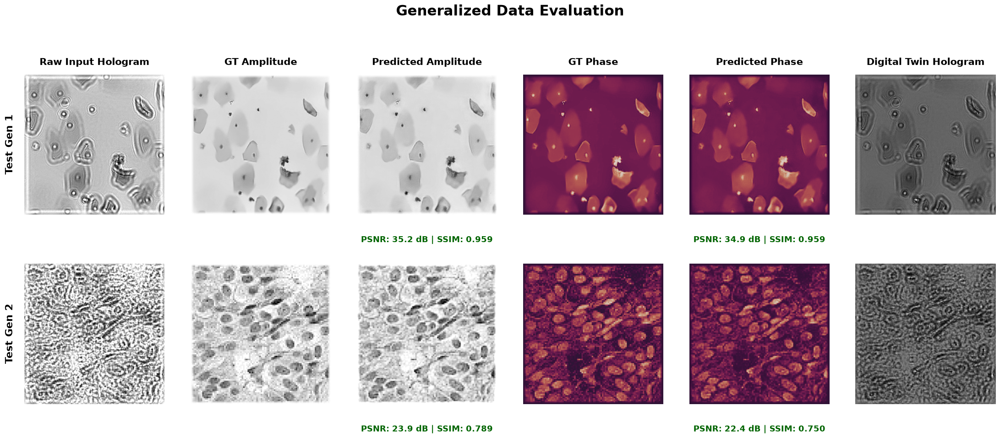

[*] Visual grid saved to: Generalized_Data_Evaluation_idx78.png


In [39]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from skimage.exposure import match_histograms
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# ============================================================================
# 1. Helpers: Auto-Loader & Data Extraction
# ============================================================================
def _load_correct_model(ckpt_path, device):
    if "Plain_UNet" in ckpt_path:
        model = PlainUNet(in_channels=12, out_channels=2).to(device)
    elif "UNetPlusPlus" in ckpt_path:
        model = UNetPlusPlus(in_channels=12, out_channels=2).to(device)
    else:
        attn = 'none'
        if 'ChannelOnly' in ckpt_path: attn = 'channel'
        elif 'SpatialOnly' in ckpt_path: attn = 'spatial'
        elif 'CBAM' in ckpt_path or 'Proposed' in ckpt_path: attn = 'cbam'
        
        use_spec = True if 'Proposed' in ckpt_path else False
        model = AblationUNet3Plus(in_channels=12, attention_type=attn, use_spectral=use_spec).to(device)
    
    checkpoint = torch.load(ckpt_path, map_location=device)
    state_dict = checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint
    model.load_state_dict(state_dict)
    model.eval()
    return model

def load_single_npz_sample_with_raw(file_path, target_size=512):
    data = np.load(file_path)
    sensor_tensor = torch.from_numpy(data['input_tensor']).float()
    
    target_amp = torch.from_numpy(data.get('target_amp', data.get('amplitude'))).float().unsqueeze(0)
    target_phase = torch.from_numpy(data.get('target_phase', data.get('phase'))).float().unsqueeze(0)
    
    a_min, a_max = target_amp.min(), target_amp.max()
    if a_max - a_min > 1e-8:
        target_amp = (target_amp - a_min) / (a_max - a_min)
    else:
        target_amp = torch.zeros_like(target_amp)
        
    target_phase = torch.atan2(torch.sin(target_phase), torch.cos(target_phase))
    
    if sensor_tensor.shape[-1] != target_size or sensor_tensor.shape[-2] != target_size:
        sensor_tensor = F.interpolate(sensor_tensor.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        target_amp = F.interpolate(target_amp.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        target_phase = F.interpolate(target_phase.unsqueeze(0), size=(target_size, target_size), mode='bilinear', align_corners=False).squeeze(0)
        
    raw_sensor = sensor_tensor.clone()
    sensor_inputs_z = (sensor_tensor - sensor_tensor.mean(dim=(-2, -1), keepdim=True)) / (sensor_tensor.std(dim=(-2, -1), keepdim=True) + 1e-8)
                      
    return sensor_inputs_z.unsqueeze(0), raw_sensor.unsqueeze(0), target_amp.unsqueeze(0), target_phase.unsqueeze(0)

# ============================================================================
# 2. Generalized Evaluation & Visualization Routine
# ============================================================================
def evaluate_generalized_data(model_ckpt, custom_datasets, forward_model, device='cuda', sample_index=0):
    device = torch.device(device if torch.cuda.is_available() else 'cpu')
    
    print(f"Loading checkpoint from: {model_ckpt}")
    model = _load_correct_model(model_ckpt, device)
    forward_model.eval()
    
    num_datasets = len(custom_datasets)
    fig, axes = plt.subplots(num_datasets, 6, figsize=(24, 4.5 * num_datasets))
    
    # Force axes to be 2D even if there is only 1 dataset provided
    axes = np.atleast_2d(axes)
    
    # --- UPDATED LAYOUT FIX ---
    # Push the main title higher up (y=1.02) to clear the column names
    fig.suptitle(f"Generalized Data Evaluation", fontsize=22, fontweight='bold', y=1.02)
    # Lower the top of the subplots (top=0.85) to give the column headers room to breathe
    fig.subplots_adjust(wspace=0.05, hspace=0.35, top=0.85, bottom=0.05, left=0.05, right=0.95)
    # --------------------------

    headers = ["Raw Input Hologram", "GT Amplitude", "Predicted Amplitude", "GT Phase", "Predicted Phase", "Digital Twin Hologram"]

    print("\n" + "="*70)
    print(" QUANTITATIVE SCORES FOR GENERALIZED DATA")
    print("="*70)

    for row_idx, (dataset_name, dir_path) in enumerate(custom_datasets.items()):
        files = sorted([f for f in glob.glob(os.path.join(dir_path, "*.npz")) if "scatterer_reference" not in os.path.basename(f)])
        if not files:
            print(f"[!] {dataset_name}: No valid .npz files found in {dir_path}")
            continue
            
        safe_idx = sample_index % len(files)
        sample_path = files[safe_idx]
        
        inp_z, raw_sens, tgt_amp, tgt_phase = load_single_npz_sample_with_raw(sample_path)
        inp_z, raw_sens = inp_z.to(device), raw_sens.to(device)
        
        with torch.no_grad():
            pred_amp, pred_phase = model(inp_z)
            pred_complex = pred_amp.to(torch.complex64) * torch.exp(1j * pred_phase.to(torch.complex64))
            sim_sensor = forward_model(pred_complex).float()
            if sim_sensor.shape != raw_sens.shape:
                sim_sensor = sim_sensor.view_as(raw_sens)

        # Convert to NumPy
        gt_a, gt_p = tgt_amp[0, 0].cpu().numpy(), tgt_phase[0, 0].cpu().numpy()
        pr_a, pr_p = pred_amp[0, 0].cpu().numpy(), pred_phase[0, 0].cpu().numpy()
        raw_s_img, sim_s_img = raw_sens[0, 0].cpu().numpy(), sim_sensor[0, 0].cpu().numpy()
        
        # Match Histogram & Compute Metrics
        pr_a = match_histograms(pr_a, gt_a)
        
        a_psnr = compute_psnr(gt_a, pr_a, data_range=1.0)
        a_ssim = compute_ssim(gt_a, pr_a, data_range=1.0)
        
        p_range = max(float(gt_p.max() - gt_p.min()), 1e-5)
        p_psnr = compute_psnr(gt_p, pr_p, data_range=p_range)
        p_ssim = compute_ssim(gt_p, pr_p, data_range=p_range)
        
        sensor_l1 = F.l1_loss(sim_sensor, raw_sens.float()).item()

        # Print Scores to Console
        print(f"Dataset: {dataset_name} | File: {os.path.basename(sample_path)}")
        print(f"  -> Amplitude : PSNR = {a_psnr:.2f} dB, SSIM = {a_ssim:.4f}")
        print(f"  -> Phase     : PSNR = {p_psnr:.2f} dB, SSIM = {p_ssim:.4f}")
        print(f"  -> Sensor L1 : {sensor_l1:.4f}\n")

        # --- Plotting ---
        axes[row_idx, 0].imshow(raw_s_img, cmap='gray')
        axes[row_idx, 0].set_ylabel(dataset_name, fontsize=16, fontweight='bold', labelpad=15)
        
        axes[row_idx, 1].imshow(gt_a, cmap='gray', vmin=0, vmax=1)
        
        axes[row_idx, 2].imshow(pr_a, cmap='gray', vmin=0, vmax=1)
        axes[row_idx, 2].text(0.5, -0.15, f"PSNR: {a_psnr:.1f} dB | SSIM: {a_ssim:.3f}", 
                              fontsize=13, fontweight='bold', color='darkgreen', ha='center', va='top', transform=axes[row_idx, 2].transAxes)
        
        axes[row_idx, 3].imshow(gt_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        
        axes[row_idx, 4].imshow(pr_p, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[row_idx, 4].text(0.5, -0.15, f"PSNR: {p_psnr:.1f} dB | SSIM: {p_ssim:.3f}", 
                              fontsize=13, fontweight='bold', color='darkgreen', ha='center', va='top', transform=axes[row_idx, 4].transAxes)
        
        axes[row_idx, 5].imshow(sim_s_img, cmap='gray')
        
        for col_idx in range(6):
            axes[row_idx, col_idx].set_xticks([])
            axes[row_idx, col_idx].set_yticks([])
            if row_idx == 0:
                axes[row_idx, col_idx].set_title(headers[col_idx], fontsize=15, fontweight='bold', pad=15)
            for spine in axes[row_idx, col_idx].spines.values():
                spine.set_visible(False)

    print("="*70)
    save_path = f"Generalized_Data_Evaluation_idx{sample_index}.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"[*] Visual grid saved to: {save_path}")

# ============================================================================
# 3. Execution Block (Customizable)
# ============================================================================
if __name__ == "__main__":
    base_dir = "/home/sakshi/Unet 3+ reconstruction"
    
    # ------------------------------------------------------------------------
    # [ACTION REQUIRED]: Add as many paths as you want here.
    # ------------------------------------------------------------------------
    custom_datasets = {
        "Test Gen 1": os.path.join(base_dir, "Digital_twin_simulation/Test_gen/NILM"), 
        "Test Gen 2": os.path.join(base_dir, "Digital_twin_simulation/Test_gen/Extracted_Images")
    }
    
    # ------------------------------------------------------------------------
    # Path to your final model and desired sample index
    # ------------------------------------------------------------------------
    FINAL_MODEL_CKPT = os.path.join(base_dir, "ablation_study_two_stage/2_UNet3Plus_NoAttention/phase2/best_phase2_model.pth")
    SAMPLE_INDEX = 78
    
    # Initialize Digital Twin Physics Model
    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    
    forward_model = LenslessMicroscope(
        led_positions=led_positions, wavelengths=wavelengths,
        sensor_pixel_size=1.55e-6, upsample_factor=2, z_total=500e-6,
        sensor_shape=(512, 512), sim_canvas_dim=1024
    ).to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
    
    evaluate_generalized_data(
        model_ckpt=FINAL_MODEL_CKPT,
        custom_datasets=custom_datasets,
        forward_model=forward_model,
        device='cuda',
        sample_index=SAMPLE_INDEX
    )